# Africa WEEE — Publication Results and Local–Global Economic Accounting (06B FINAL)

**Publication-facing notebook. Physical modelling remains frozen in Notebooks 01–05.**

This notebook implements the local–global economic accounting used in the manuscript. The analysis distinguishes between effects borne primarily in African countries and broader benefits associated with formalisation.

---

## Local effects

The local account combines the PM-related health burden of current informal WEEE management with the economic value associated with informal material recovery:

$$
\mathbf{Local\ effects}
=
\mathbf{Air\ pollution\ health\ damage}
-
\left(
\mathbf{Informal\ recovery}
\times
\mathbf{Metal\ price}
\right)
$$

where:

- **Air-pollution health damage** = monetised PM-related health burden under **current informal management**.
- **Informal recovery × metal price** = gross reference-market value of informally recovered **Cu, Ag, Au and Pd**.

The second term is used as a **proxy for livelihood-related economic value**. It is not observed worker income, wages, or profits.

---

## Global effects

The global account captures the broader climate and resource benefits associated with formalisation:

$$
\mathbf{Global\ effects}
=
\mathbf{Avoided\ GHG\ damage}
+
\mathbf{Net\ mineral\ recovery\ gain}
$$

where:

- **Avoided GHG damage** = monetised reduction in GWP between current informal management and the formal-treatment counterfactual.
- **Net mineral recovery gain** = market value of the **additional Cu, Ag, Au and Pd recovered under formal treatment relative to current informal management**.

---

## Interpretation

The two accounts answer different questions:

**Local:** What is the balance between the health burden generated by current informal management and the economic value associated with informal material recovery?

**Global:** What climate and resource benefits could be generated by moving from current informal management to formal treatment?

The local and global accounts are therefore **reported separately** and are **not added together into a net social benefit or benefit–cost ratio**.

---

## Valuation cases

**Low, Central and High are monetary valuation cases, not physical scenarios or confidence intervals.**

- **PM-health:** €50,000 / €100,000 / €150,000 per DALY
- **Climate:** €50 / €185 / €300 per t CO₂-eq
- **Physical quantities:** WEEE, PM impacts, GWP impacts, CRM quantities, recovery rates and metal prices remain unchanged across the three cases.

In [1]:
# CELL 1 — IMPORTS, PATHS, LABELS, STYLE

from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.gridspec as gridspec
from matplotlib.colors import PowerNorm

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

PROJECT_DIR = Path.cwd()
ACTIVITY_DIR = PROJECT_DIR / "ewaste_activity_results" / "v2_electricity_baseline"
LCA_CANDIDATES = [PROJECT_DIR / "03_Africa_LCA_scaling_outputs", PROJECT_DIR]
CRM_DIR = PROJECT_DIR / "05_CRM_recovery_outputs" / "v3_final"

FIG_DIR = PROJECT_DIR / "06B_paper_outputs" / "figures"
TABLE_DIR = PROJECT_DIR / "06B_paper_outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

ACTIVITY_FILES = {
    "ewaste": ACTIVITY_DIR / "ewaste_generated_country_year_product.csv",
    "pom": ACTIVITY_DIR / "pom_country_year_product.csv",
    "country_year": ACTIVITY_DIR / "ewaste_generated_country_year.csv",
    "meta": ACTIVITY_DIR / "run_metadata.json",
}
LCA_REQUIRED = [
    "africa_year_lcia.csv",
    "country_year_lcia.csv",
    "country_year_product_lcia_long.csv",
    "country_year_formal_informal_comparison.csv",
    "product_group_lcia_coefficients.csv",
    "run_metadata_03.json",
]
LCA_DIR = next((p for p in LCA_CANDIDATES if all((p/f).exists() for f in LCA_REQUIRED)), None)

CRM_FILES = {
    "available_cumulative": CRM_DIR / "crm_available_cumulative.csv",
    "available_year": CRM_DIR / "crm_available_africa_year.csv",
    "recovery_year": CRM_DIR / "crm_recovery_africa_year.csv",
    "additional_recovery": CRM_DIR / "crm_forgone_recovery_cumulative.csv",
    "available_country_year_product": CRM_DIR / "crm_available_country_year_product.csv",
    "recovery_parameters": CRM_DIR / "crm_recovery_parameters.csv",
    "meta": CRM_DIR / "run_metadata_05.json",
}

for label, path in ACTIVITY_FILES.items():
    assert path.exists(), f"Missing Notebook 02 output ({label}): {path}"
assert LCA_DIR is not None, "Could not locate Notebook 03 outputs."
for label, path in CRM_FILES.items():
    assert path.exists(), f"Missing Notebook 05 output ({label}): {path}"

S_CURRENT = "Africa informal"
S_FORMAL = "Africa formal"
LABEL_CURRENT = "Current informal-management baseline"
LABEL_FORMAL = "Formal-treatment counterfactual"

PRODUCT_ORDER = [
    "Cooling equipment","Lighting","Other equipment","Large household appliances",
    "Screens","Small household appliances","Ventilation equipment",
    "Telecom equipment","IT equipment","Electric tools",
]
PRODUCT_COLORS = {p: plt.get_cmap("tab10")(i % 10) for i,p in enumerate(PRODUCT_ORDER)}

COL_CURRENT = "#D95F02"
COL_FORMAL = "#1B9E77"

plt.rcParams.update({
    "font.family":"sans-serif",
    "font.size":10,
    "axes.titlesize":11,
    "axes.labelsize":10,
    "axes.spines.top":False,
    "axes.spines.right":False,
    "figure.dpi":130,
    "savefig.dpi":600,
})

print("Activity:", ACTIVITY_DIR)
print("LCA:", LCA_DIR)
print("CRM:", CRM_DIR)

Activity: C:\Users\uribep_a\OneDrive - Paul Scherrer Institut\general_LCA\ewaste_activity_results\v2_electricity_baseline
LCA: C:\Users\uribep_a\OneDrive - Paul Scherrer Institut\general_LCA\03_Africa_LCA_scaling_outputs
CRM: C:\Users\uribep_a\OneDrive - Paul Scherrer Institut\general_LCA\05_CRM_recovery_outputs\v3_final


In [2]:
# CELL 2 — LOAD OFFICIAL OUTPUTS + PROVENANCE

ewaste = pd.read_csv(ACTIVITY_FILES["ewaste"])
pom = pd.read_csv(ACTIVITY_FILES["pom"])
activity_country_year = pd.read_csv(ACTIVITY_FILES["country_year"])

africa_lcia = pd.read_csv(LCA_DIR / "africa_year_lcia.csv")
country_lcia = pd.read_csv(LCA_DIR / "country_year_lcia.csv")
product_lcia = pd.read_csv(LCA_DIR / "country_year_product_lcia_long.csv")
comparison = pd.read_csv(LCA_DIR / "country_year_formal_informal_comparison.csv")

crm_available_cum = pd.read_csv(CRM_FILES["available_cumulative"])
crm_available_year = pd.read_csv(CRM_FILES["available_year"])
crm_recovery_year = pd.read_csv(CRM_FILES["recovery_year"])
crm_additional = pd.read_csv(CRM_FILES["additional_recovery"])

with open(ACTIVITY_FILES["meta"], encoding="utf-8") as f: meta02 = json.load(f)
with open(LCA_DIR / "run_metadata_03.json", encoding="utf-8") as f: meta03 = json.load(f)
with open(CRM_FILES["meta"], encoding="utf-8") as f: meta05 = json.load(f)

assert meta02.get("apply_electricity_adjustment") is True
assert set(africa_lcia["Scenario"].unique()) == {S_CURRENT, S_FORMAL}
assert set(product_lcia["Method"].unique()) == {"GWP", "PM_formation"}
assert meta03.get("avoided_primary_production_credits_included") is False
assert meta03.get("monetization_included") is False
assert meta05.get("prices_included") is False
assert meta05.get("monetization_included") is False
assert set(meta05.get("crm_codes_with_recovery_scenarios", [])) == {"Ag","Au","Cu","Pd"}

YEARS = sorted(ewaste["Year"].astype(int).unique())
YEAR0, YEAR1 = min(YEARS), max(YEARS)

print(f"Period: {YEAR0}–{YEAR1}")
print(f"Countries: {ewaste['ISO3'].nunique()}")
print("✓ Provenance checks passed")

Period: 2014–2024
Countries: 54
✓ Provenance checks passed


# Figure 1 — Magnitude and evolution of the flow

A deliberately simple opening figure:
- **A:** EEE imports/POM by product group.
- **B:** modelled WEEE generation by product group.

The Africa map is separated into Figure 2 so that geography has enough visual space.

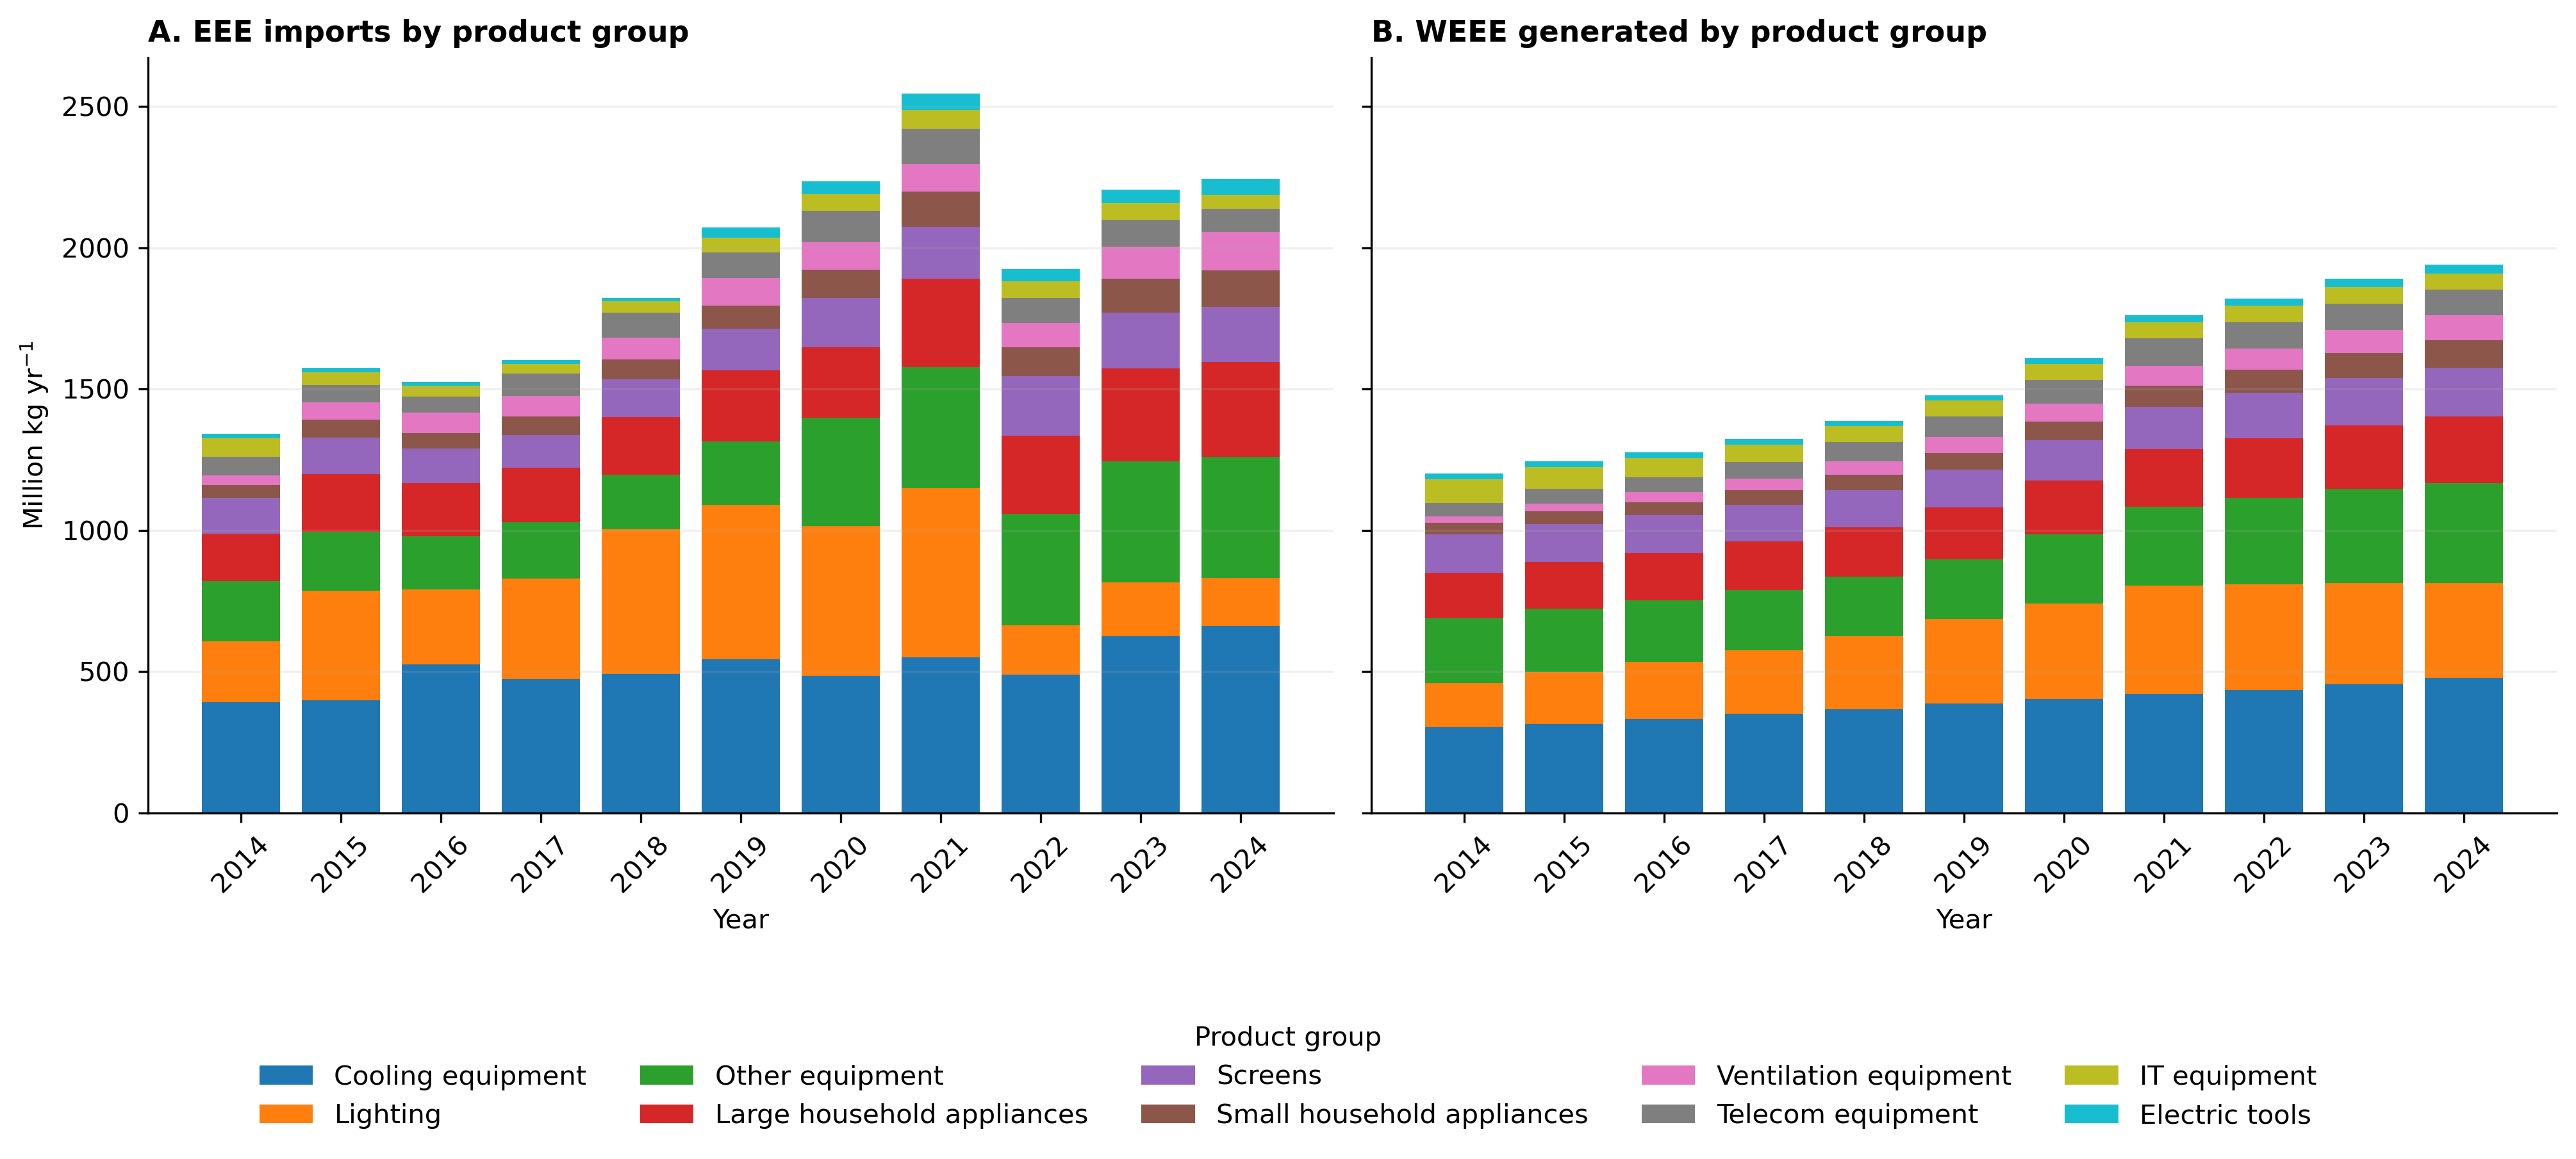

In [3]:
# CELL 3 — FIGURE 1: FLOW ONLY

pom_plot = pom.groupby(["Year","ProductGroup"], as_index=False)["POM_kg"].sum()
ew_plot = ewaste.groupby(["Year","ProductGroup"], as_index=False)["EWasteGenerated_kg"].sum()

pom_wide = pom_plot.pivot(index="Year",columns="ProductGroup",values="POM_kg").fillna(0)/1e6
ew_wide = ew_plot.pivot(index="Year",columns="ProductGroup",values="EWasteGenerated_kg").fillna(0)/1e6

order = [p for p in PRODUCT_ORDER if p in ew_wide.columns]
order += [p for p in ew_wide.columns if p not in order]

fig, axes = plt.subplots(1,2,figsize=(13.5,5.5),dpi=300,sharey=True)

for ax, wide, title in [
    (axes[0],pom_wide,"A. EEE imports by product group"),
    (axes[1],ew_wide,"B. WEEE generated by product group")
]:
    bottom=np.zeros(len(wide))
    for p in order:
        vals=wide[p].values if p in wide.columns else np.zeros(len(wide))
        ax.bar(wide.index.astype(str),vals,bottom=bottom,label=p,
               color=PRODUCT_COLORS.get(p),width=0.78)
        bottom += vals
    ax.set_title(title,loc="left",weight="bold")
    ax.set_xlabel("Year")
    ax.tick_params(axis="x",rotation=45)
    ax.grid(axis="y",alpha=.18)

axes[0].set_ylabel("Million kg yr$^{-1}$")

handles,labels=axes[1].get_legend_handles_labels()
fig.legend(handles,labels,title="Product group",ncol=5,
           loc="lower center",bbox_to_anchor=(.5,-.10),frameon=False)

plt.tight_layout(rect=[0,.08,1,1])
plt.savefig(FIG_DIR/"Figure1_EEE_WEEE_flow.png",bbox_inches="tight")
plt.savefig(FIG_DIR/"Figure1_EEE_WEEE_flow.pdf",bbox_inches="tight")
plt.show()

# Figure 2 — Geography of WEEE generation

A full-size Africa map showing WEEE generated in the final observation year. This is kept separate from Figure 1 to preserve legibility and give the geographic result its own message.

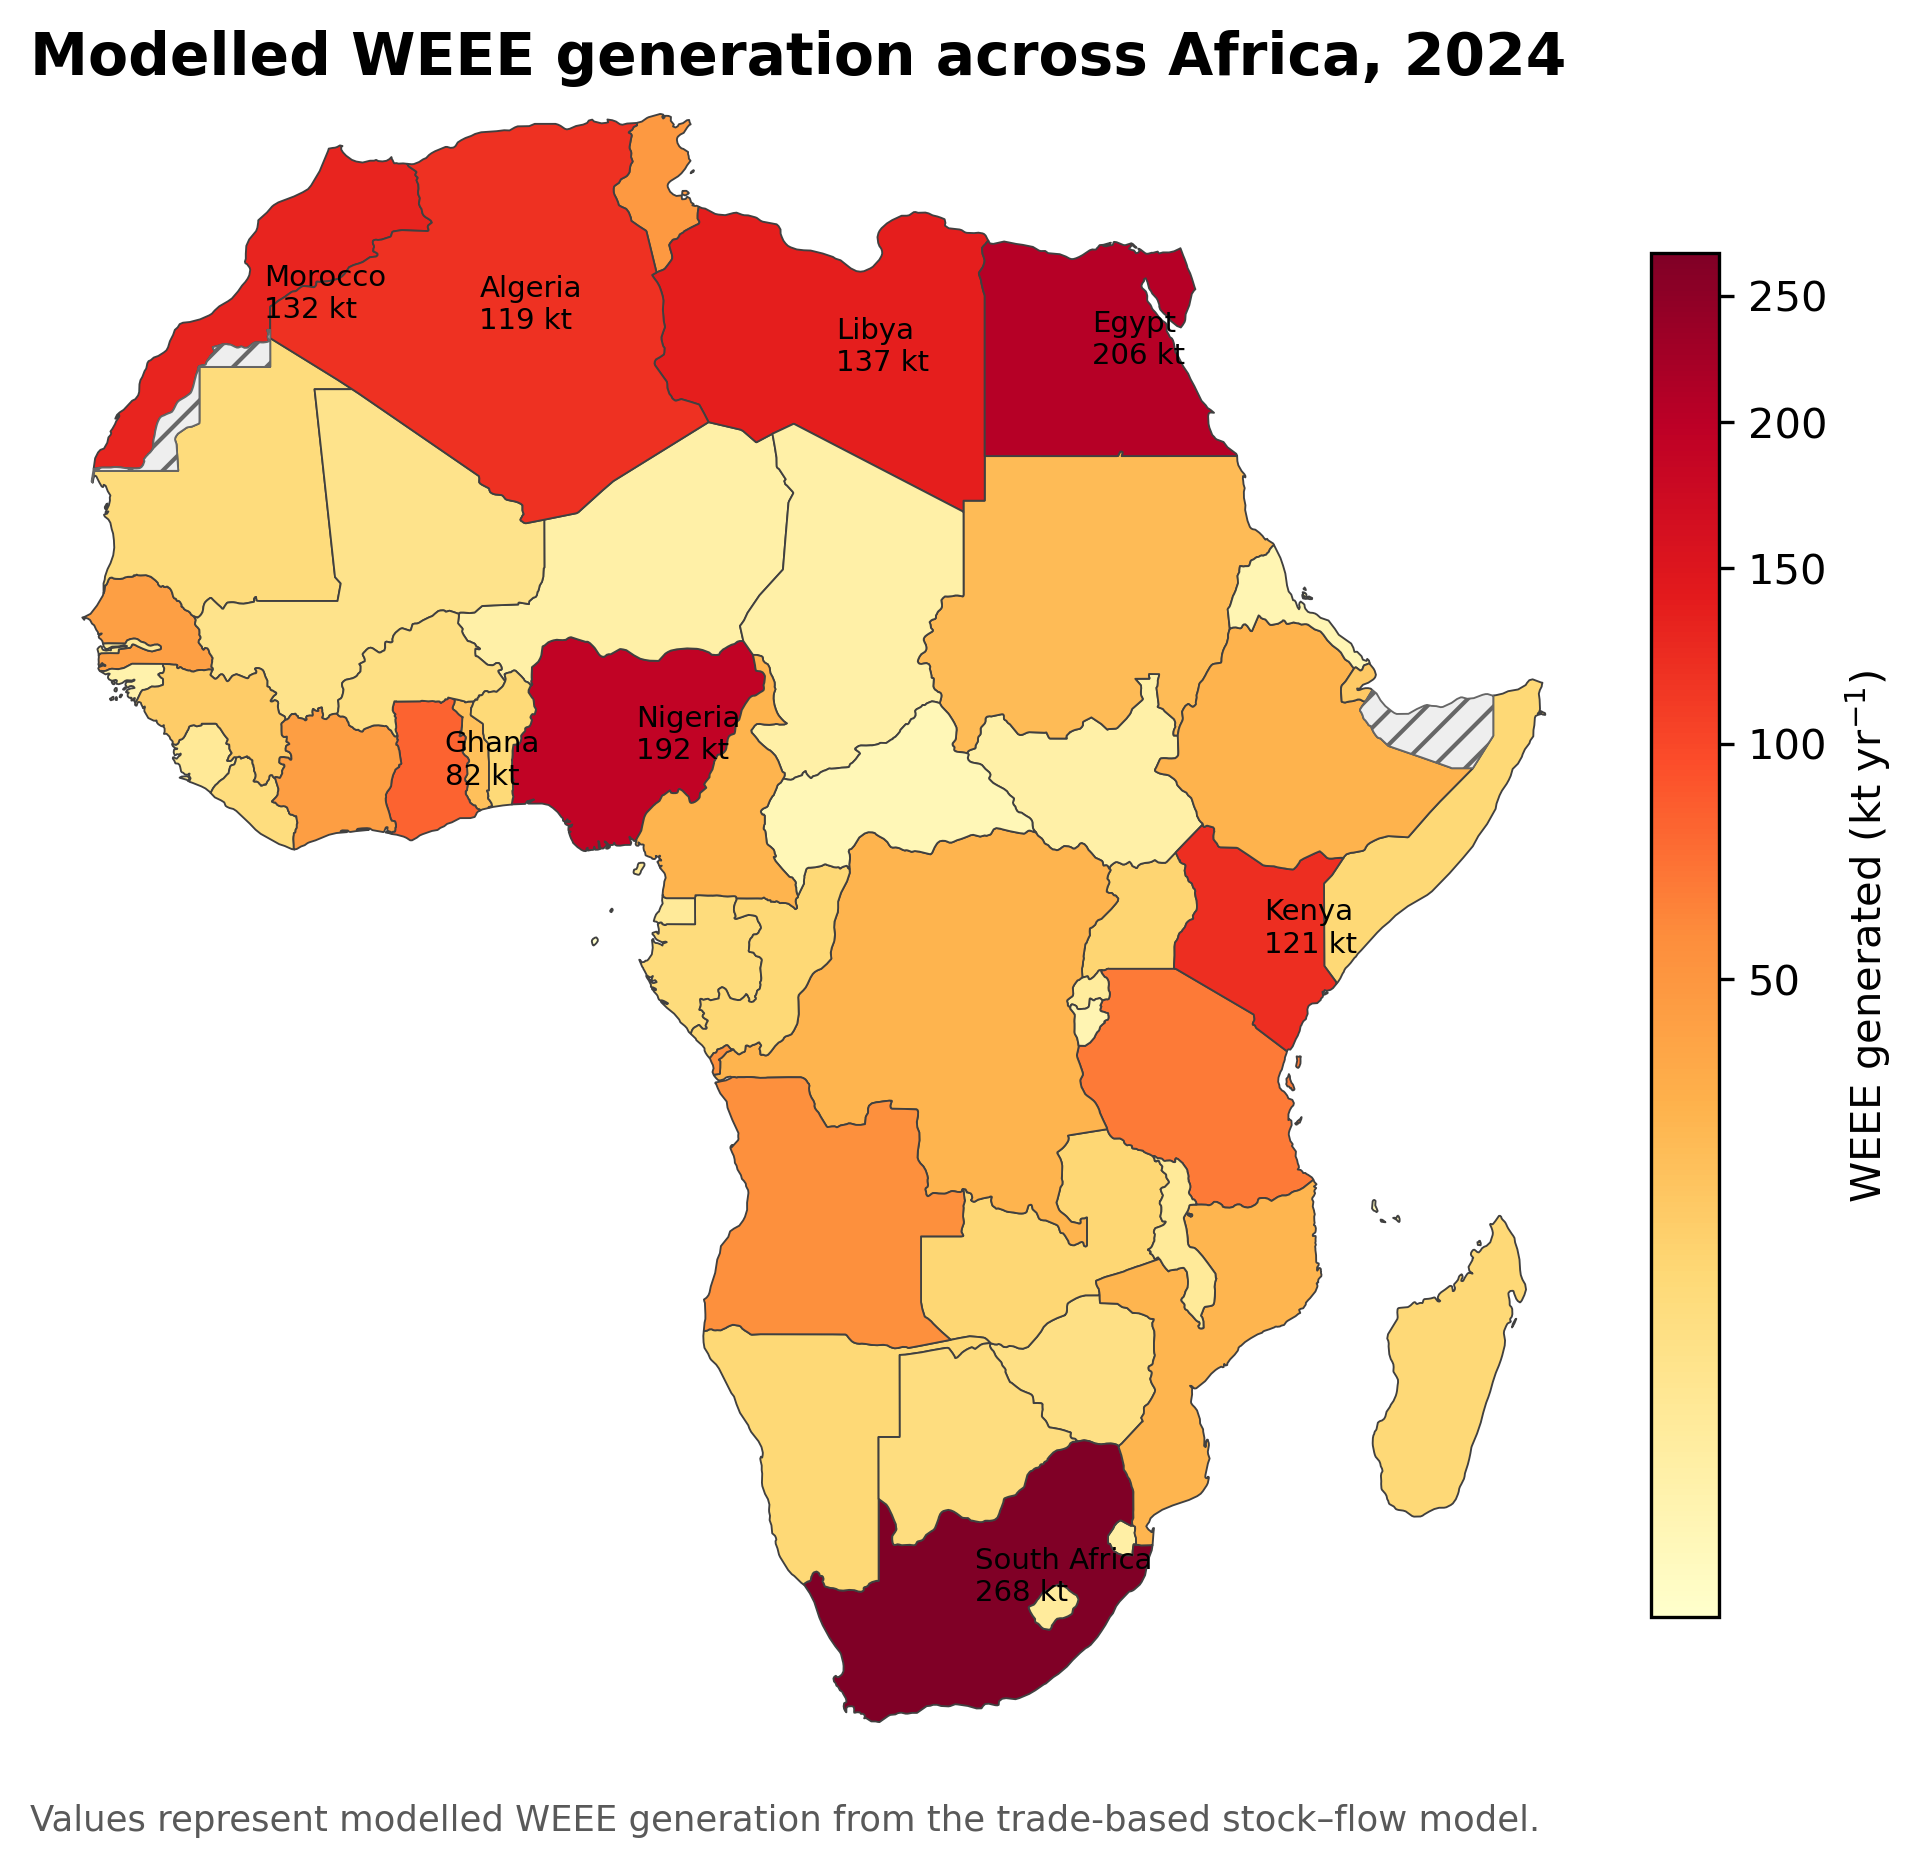

In [4]:
# CELL 4 — FIGURE 2: AFRICA WEEE MAP

map_data = (
    ewaste[ewaste["Year"]==YEAR1]
    .groupby(["ISO3","Country"],as_index=False)["EWasteGenerated_kg"].sum()
)
map_data["ewaste_kt"]=map_data["EWasteGenerated_kg"]/1e6

fig,ax=plt.subplots(figsize=(8.2,8.2),dpi=300)

try:
    import geopandas as gpd
    NE_URL="https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip"
    world=gpd.read_file(NE_URL)

    world["iso3"]=np.nan
    for c in [c for c in ["ISO_A3","ADM0_A3","SOV_A3"] if c in world.columns]:
        world["iso3"]=world["iso3"].fillna(world[c].replace("-99",np.nan))

    africa=world[world["CONTINENT"]=="Africa"].copy()
    africa=africa.merge(map_data,left_on="iso3",right_on="ISO3",how="left")

    valid=africa["ewaste_kt"].dropna()
    norm=PowerNorm(gamma=.45,vmin=max(valid.min(),1e-12),vmax=valid.max())

    africa.plot(column="ewaste_kt",cmap="YlOrRd",norm=norm,
                linewidth=.45,edgecolor=".25",ax=ax,
                missing_kwds={"color":"#eeeeee","edgecolor":".4","hatch":"///"})

    top=africa.dropna(subset=["ewaste_kt"]).nlargest(8,"ewaste_kt").copy()
    pts=top.to_crs(3857).representative_point().to_crs(4326)
    top["_x"],top["_y"]=pts.x,pts.y
    for _,r in top.iterrows():
        label=r["Country"] if pd.notna(r["Country"]) else r["iso3"]
        ax.text(r["_x"]+.6,r["_y"]+.4,
                f"{label}\n{r['ewaste_kt']:.0f} kt",
                fontsize=7,ha="left",va="center")

    sm=mpl.cm.ScalarMappable(cmap="YlOrRd",norm=norm); sm.set_array([])
    cb=fig.colorbar(sm,ax=ax,shrink=.72,pad=.015)
    cb.set_label("WEEE generated (kt yr$^{-1}$)")

    ax.set_xlim(-20,55); ax.set_ylim(-37,38); ax.axis("off")
    ax.set_title(f"Modelled WEEE generation across Africa, {YEAR1}",
                 loc="left",fontsize=14,weight="bold")
    ax.text(0,-.035,
            "Values represent modelled WEEE generation from the trade-based stock–flow model.",
            transform=ax.transAxes,fontsize=8.5,color=".35")

except Exception as exc:
    ax.text(.5,.5,f"Map not rendered:\n{exc}",ha="center",va="center")
    ax.axis("off")
    warnings.warn(str(exc))

plt.savefig(FIG_DIR/"Figure2_Africa_WEEE_map.png",bbox_inches="tight")
plt.savefig(FIG_DIR/"Figure2_Africa_WEEE_map.pdf",bbox_inches="tight")
plt.show()

# Figure 3 — Local health burden vs global climate burden

This figure carries the central conceptual result of the paper.

- **Local:** PM-health burden is assigned to the African countries where current informal WEEE treatment occurs.
- **Global:** climate damages from GHG emissions are treated as global externalities.

The formal-treatment case is a counterfactual benchmark, not a second observed historical scenario.

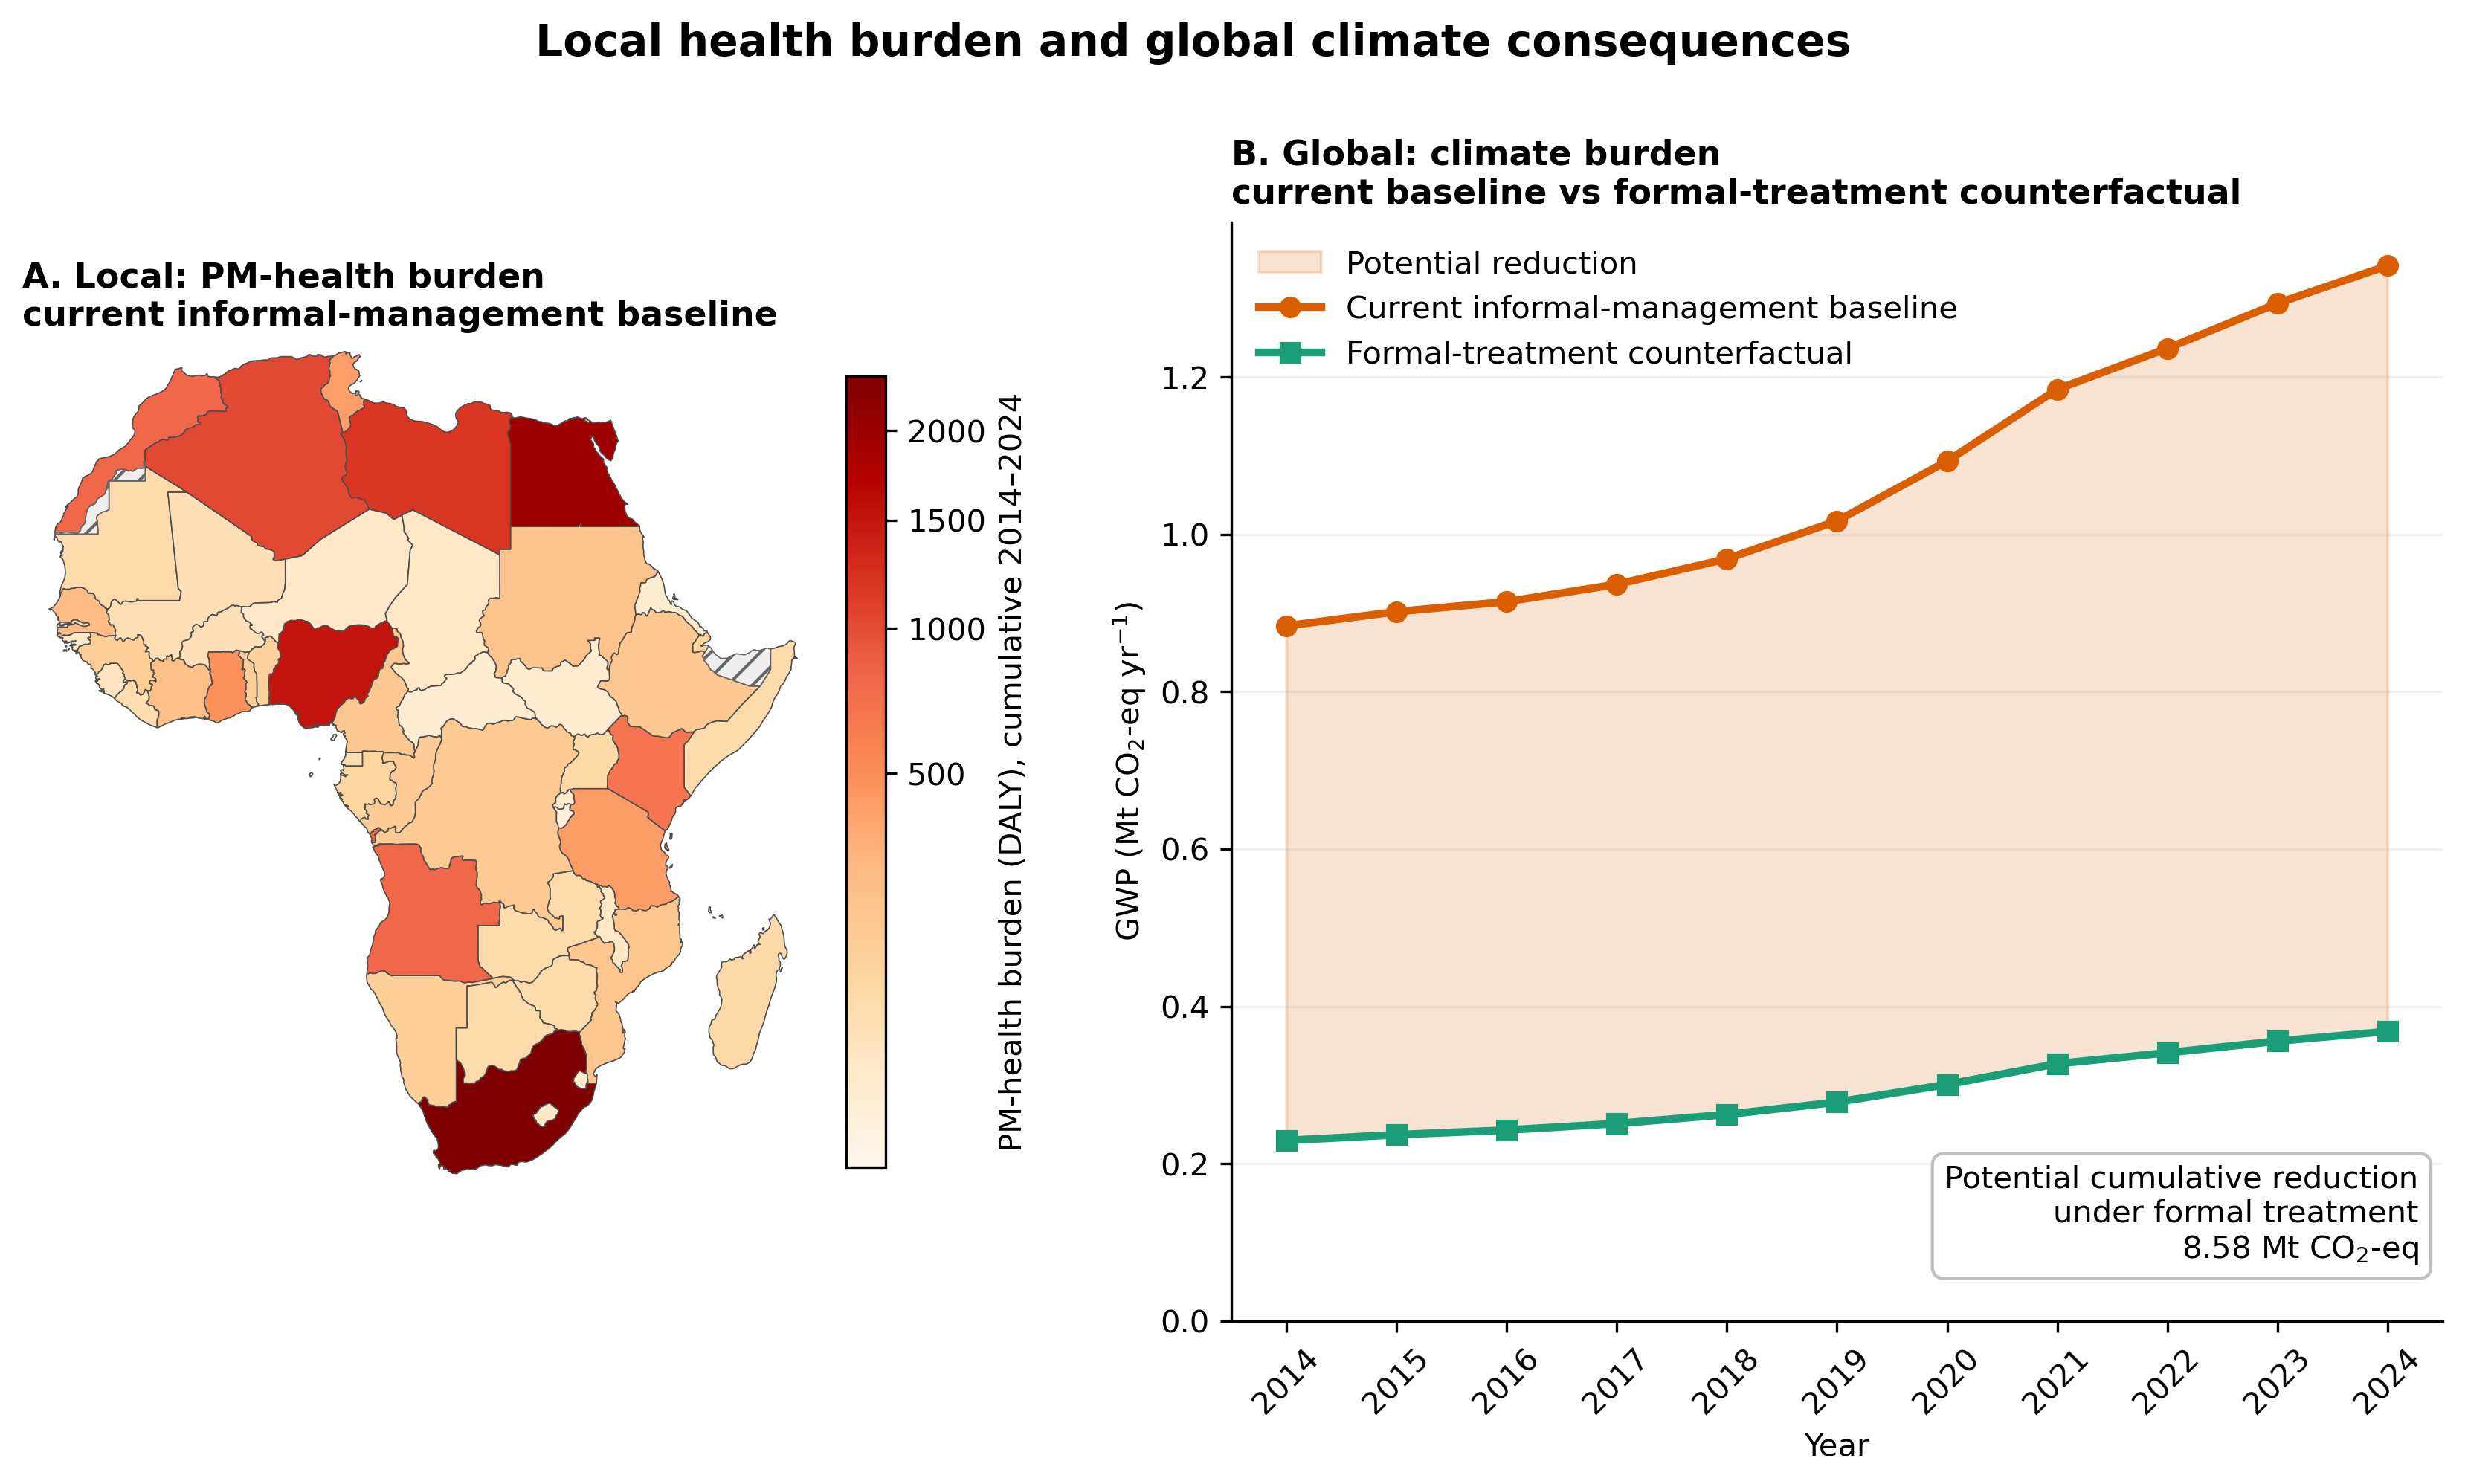

In [5]:
# CELL 5 — FIGURE 3: LOCAL HEALTH + GLOBAL CLIMATE

health = (
    country_lcia[country_lcia["Scenario"]==S_CURRENT]
    .groupby(["ISO3","Country"],as_index=False)["PM_DALY"].sum()
    .rename(columns={"PM_DALY":"DALY"})
)
gwp=(africa_lcia.pivot(index="Year",columns="Scenario",values="GWP_kgCO2eq").sort_index()/1e9)
gwp_delta=float((gwp[S_CURRENT]-gwp[S_FORMAL]).sum())

fig=plt.figure(figsize=(14,6.4),dpi=300)
gs=gridspec.GridSpec(1,2,width_ratios=[1,1.25],wspace=.22)
ax1=fig.add_subplot(gs[0,0]); ax2=fig.add_subplot(gs[0,1])

try:
    import geopandas as gpd
    NE_URL="https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip"
    world=gpd.read_file(NE_URL)
    world["iso3"]=np.nan
    for c in [c for c in ["ISO_A3","ADM0_A3","SOV_A3"] if c in world.columns]:
        world["iso3"]=world["iso3"].fillna(world[c].replace("-99",np.nan))
    africa=world[world["CONTINENT"]=="Africa"].copy().merge(
        health,left_on="iso3",right_on="ISO3",how="left"
    )
    valid=africa["DALY"].dropna()
    norm=PowerNorm(gamma=.45,vmin=max(valid.min(),1e-12),vmax=valid.max())
    africa.plot(column="DALY",cmap="OrRd",norm=norm,linewidth=.4,
                edgecolor=".3",ax=ax1,
                missing_kwds={"color":"#eeeeee","edgecolor":".4","hatch":"///"})
    sm=mpl.cm.ScalarMappable(cmap="OrRd",norm=norm); sm.set_array([])
    cb=fig.colorbar(sm,ax=ax1,shrink=.72,pad=.01)
    cb.set_label(f"PM-health burden (DALY), cumulative {YEAR0}–{YEAR1}")
    ax1.set_xlim(-20,55); ax1.set_ylim(-37,38); ax1.axis("off")
except Exception as exc:
    ax1.text(.5,.5,str(exc),ha="center",va="center"); ax1.axis("off")

ax1.set_title("A. Local: PM-health burden\ncurrent informal-management baseline",
              loc="left",weight="bold")

years=gwp.index.values
cur=gwp[S_CURRENT].values
formal=gwp[S_FORMAL].values
ax2.fill_between(years,formal,cur,where=cur>=formal,
                 color=COL_CURRENT,alpha=.18,label="Potential reduction")
ax2.plot(years,cur,color=COL_CURRENT,lw=2.5,marker="o",label=LABEL_CURRENT)
ax2.plot(years,formal,color=COL_FORMAL,lw=2.5,marker="s",label=LABEL_FORMAL)
ax2.set_ylabel("GWP (Mt CO$_2$-eq yr$^{-1}$)")
ax2.set_xlabel("Year")
ax2.set_xticks(years); ax2.tick_params(axis="x",rotation=45)
ax2.set_ylim(bottom=0); ax2.grid(axis="y",alpha=.18)
ax2.legend(frameon=False)
ax2.text(.98,.05,
         f"Potential cumulative reduction\nunder formal treatment\n{gwp_delta:.2f} Mt CO$_2$-eq",
         transform=ax2.transAxes,ha="right",va="bottom",
         bbox=dict(boxstyle="round,pad=.4",fc="white",ec=".75"))
ax2.set_title("B. Global: climate burden\ncurrent baseline vs formal-treatment counterfactual",
              loc="left",weight="bold")

fig.suptitle("Local health burden and global climate consequences",
             fontsize=14,weight="bold",y=1.02)
plt.savefig(FIG_DIR/"Figure3_local_health_global_climate.png",bbox_inches="tight")
plt.savefig(FIG_DIR/"Figure3_local_health_global_climate.pdf",bbox_inches="tight")
plt.show()

# Figure 4 — Product groups driving current burdens

This figure stays descriptive: it explains which product groups dominate the two environmental indicators under current informal management. Formalisation potential is kept for the economic synthesis rather than adding four competing panels here.

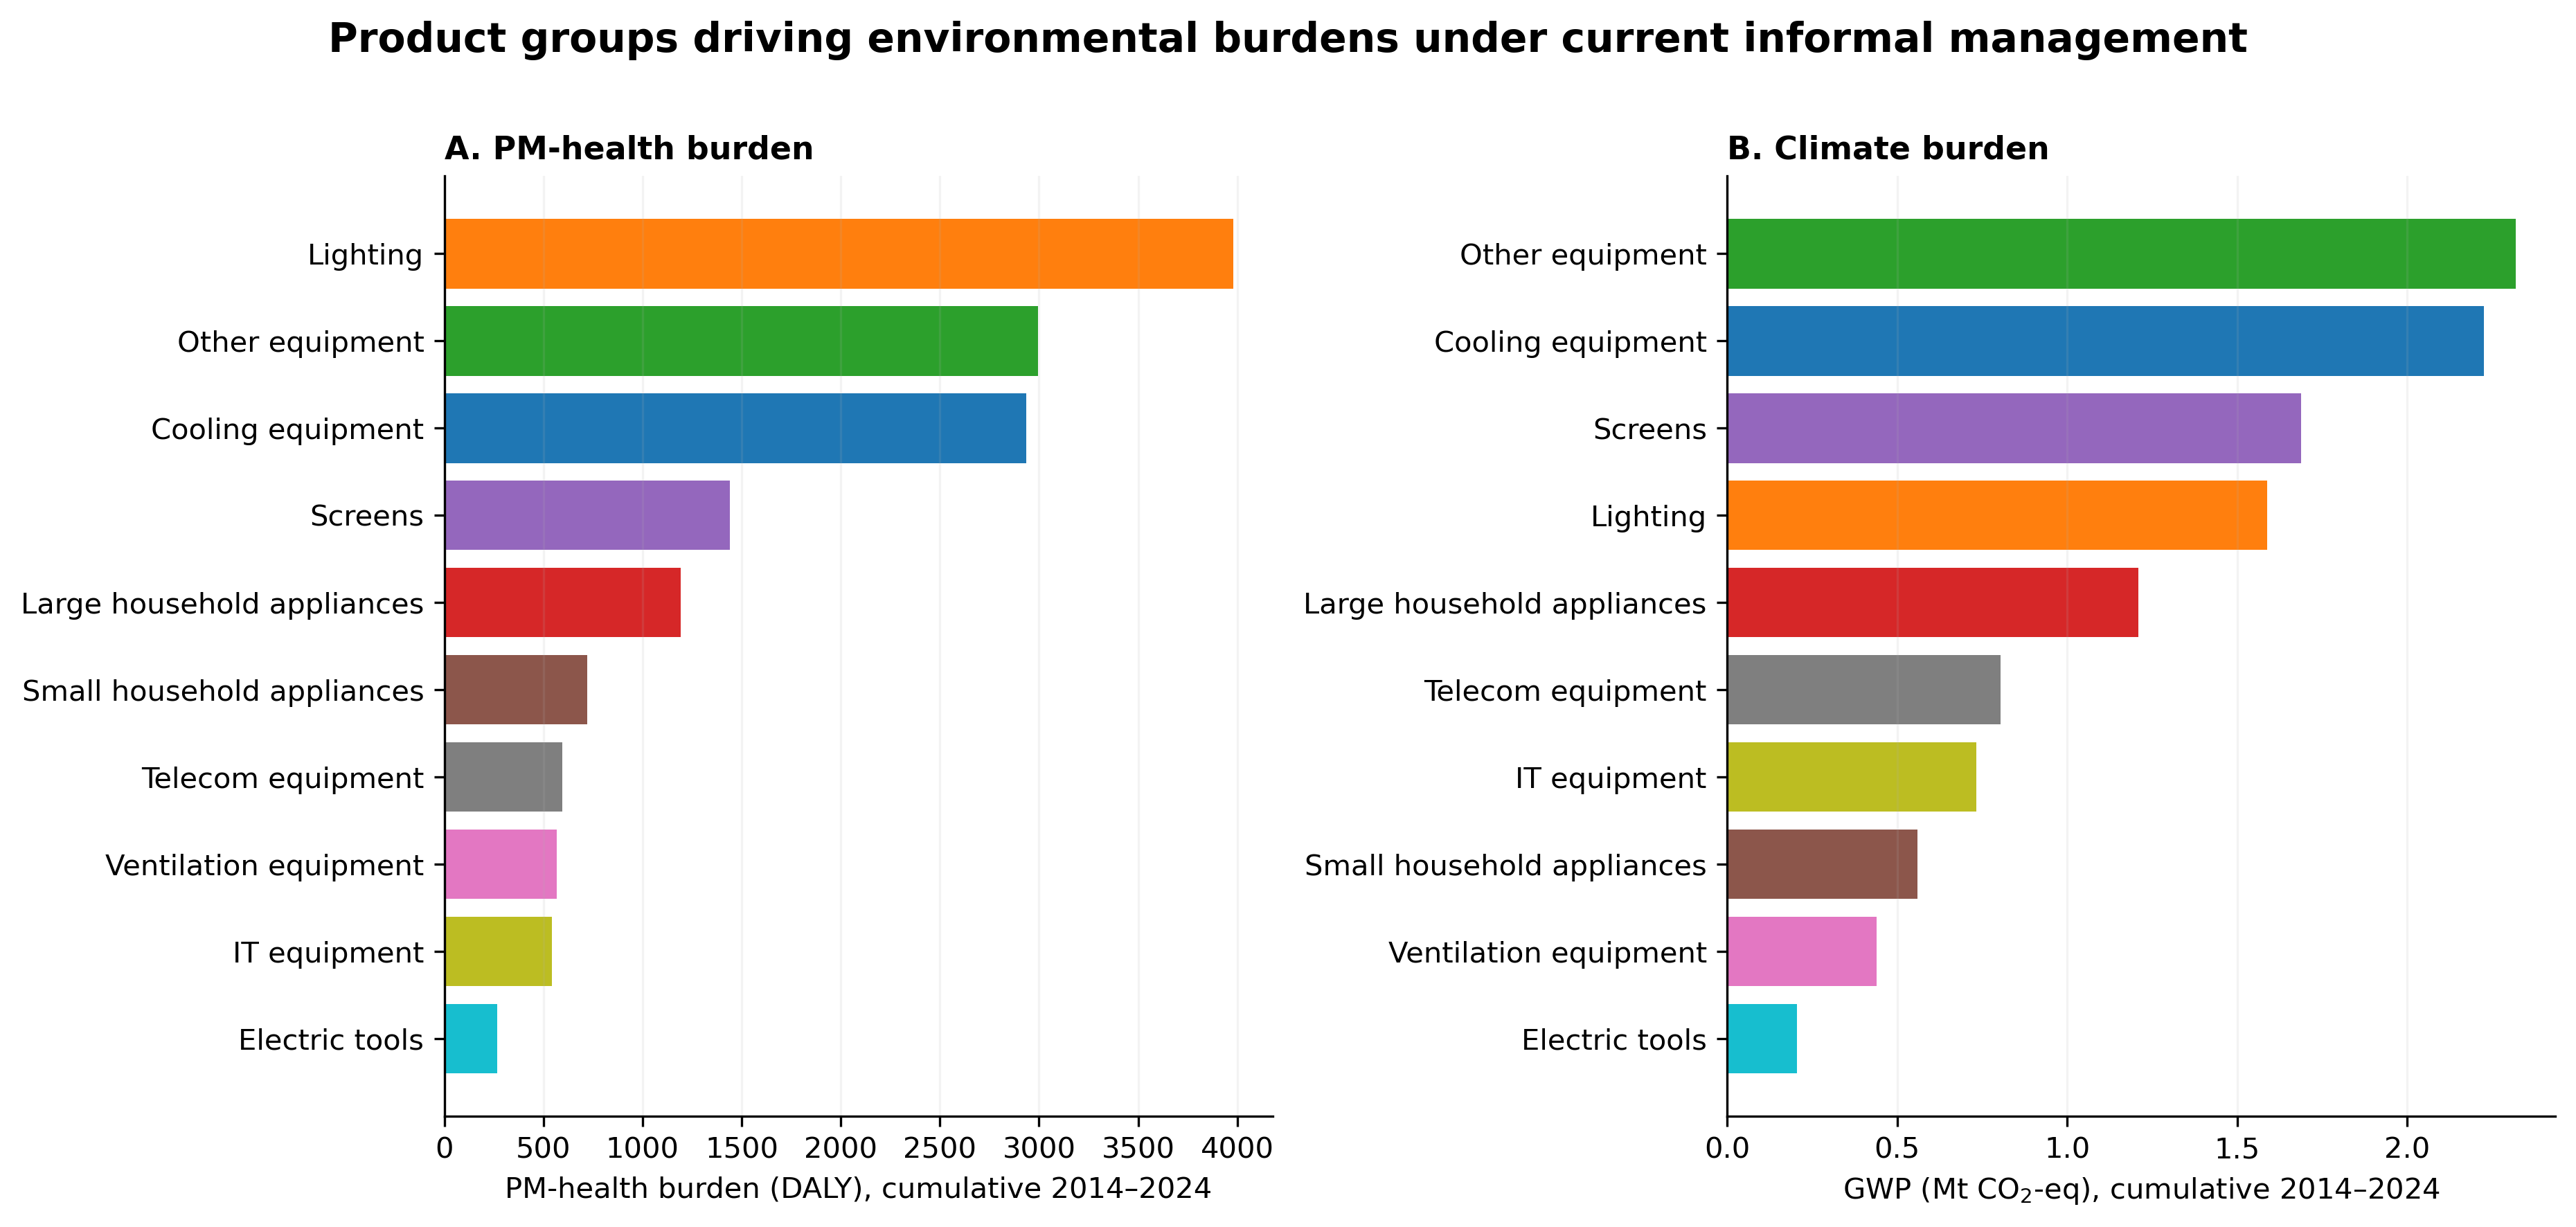

In [6]:
# CELL 6 — FIGURE 4: PRODUCT-GROUP DRIVERS

prod=product_lcia[product_lcia["Scenario"]==S_CURRENT].groupby(
    ["ProductGroup","Method"],as_index=False)["Impact"].sum()

pm=prod[prod["Method"]=="PM_formation"].copy().sort_values("Impact")
gwp_p=prod[prod["Method"]=="GWP"].copy().sort_values("Impact")
gwp_p["Impact_Mt"]=gwp_p["Impact"]/1e9

fig,axes=plt.subplots(1,2,figsize=(12.5,5.8),dpi=300)

axes[0].barh(pm["ProductGroup"],pm["Impact"],
             color=[PRODUCT_COLORS.get(p) for p in pm["ProductGroup"]])
axes[0].set_xlabel(f"PM-health burden (DALY), cumulative {YEAR0}–{YEAR1}")
axes[0].set_title("A. PM-health burden",loc="left",weight="bold")
axes[0].grid(axis="x",alpha=.15)

axes[1].barh(gwp_p["ProductGroup"],gwp_p["Impact_Mt"],
             color=[PRODUCT_COLORS.get(p) for p in gwp_p["ProductGroup"]])
axes[1].set_xlabel(f"GWP (Mt CO$_2$-eq), cumulative {YEAR0}–{YEAR1}")
axes[1].set_title("B. Climate burden",loc="left",weight="bold")
axes[1].grid(axis="x",alpha=.15)

fig.suptitle("Product groups driving environmental burdens under current informal management",
             fontsize=14,weight="bold",y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR/"Figure4_product_drivers.png",bbox_inches="tight")
plt.savefig(FIG_DIR/"Figure4_product_drivers.pdf",bbox_inches="tight")
plt.show()

# Figure 5 — Critical raw materials: physical results only

The CRM figure deliberately **does not use error bars**. Low/high recovery cases are scenario assumptions, not statistical confidence intervals.

- **A:** all 18 tracked CRM physically embedded in WEEE.
- **B:** central estimate of additional recoverable Cu, Ag, Au and Pd under the formal-treatment counterfactual.

The economic value of these materials is introduced separately below.

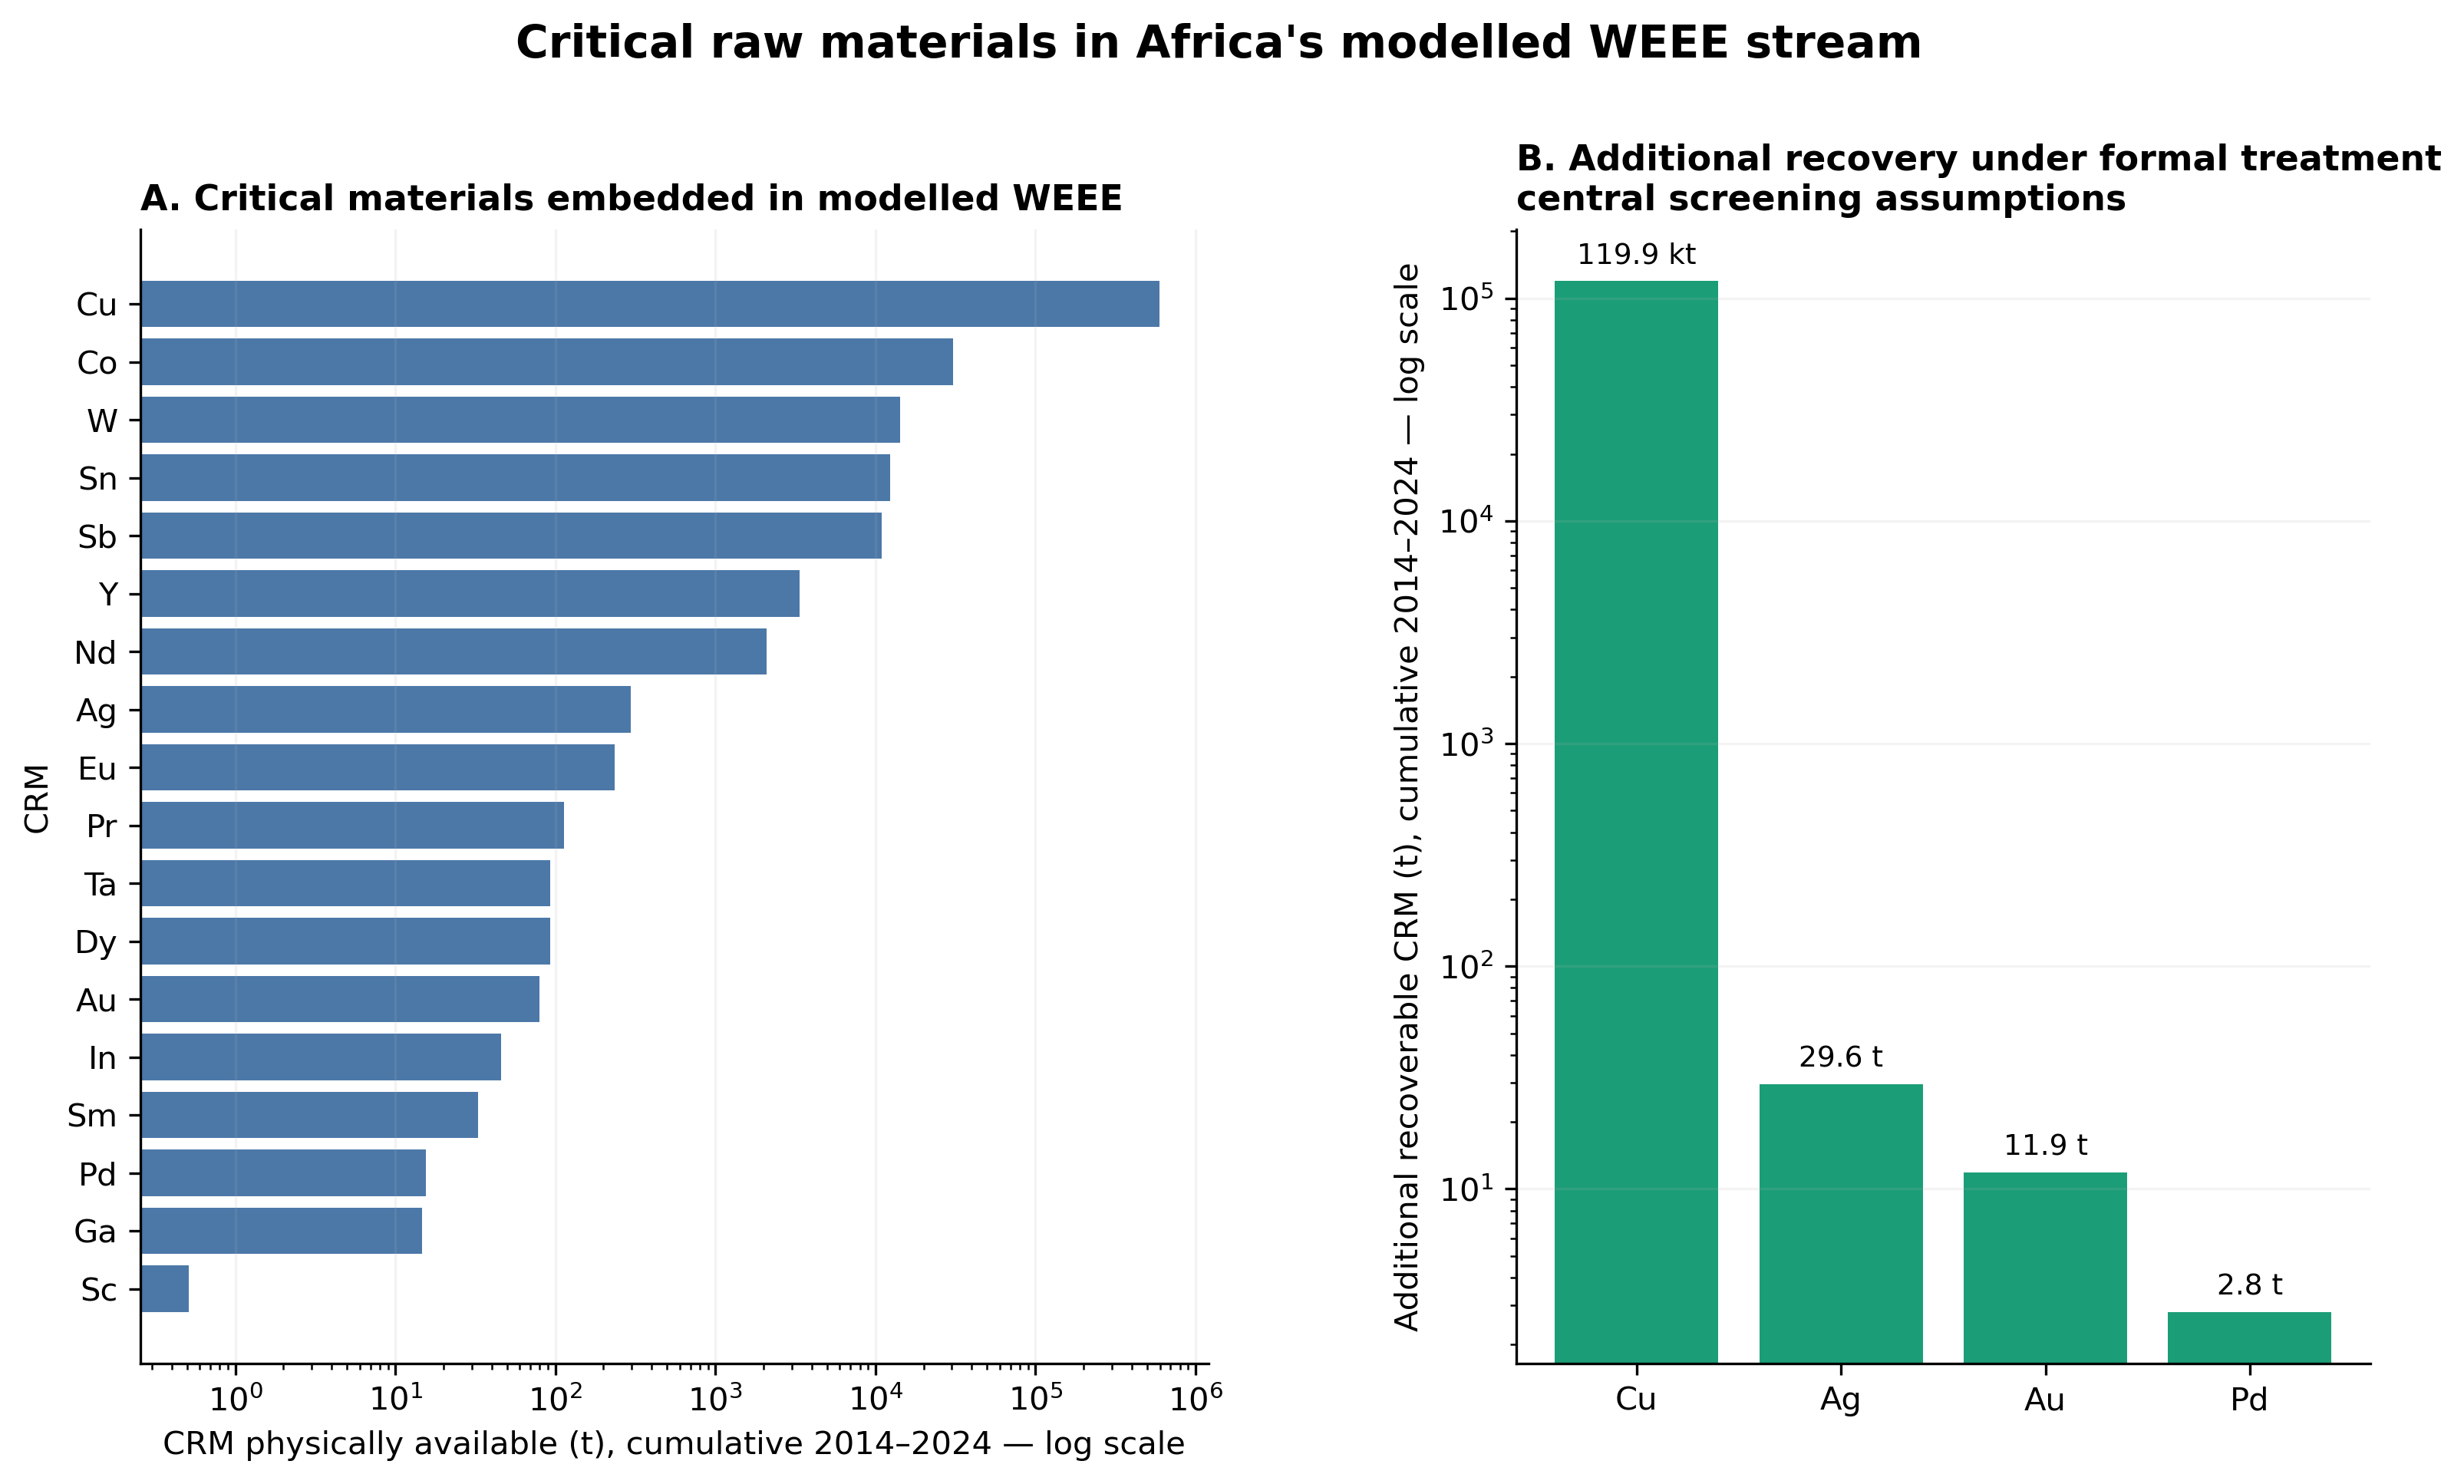

In [7]:
# CELL 7 — FIGURE 5: CRM PHYSICAL RESULTS, NO UNCERTAINTY BARS

crm=crm_available_cum.copy()
crm["available_t"]=crm["CRM_available_kg"]/1000
crm=crm.sort_values("available_t")

add=crm_additional.copy()
add["central_t"]=add["Forgone_central_kg"]/1000

fig=plt.figure(figsize=(12.5,6.4),dpi=300)
gs=gridspec.GridSpec(1,2,width_ratios=[1.25,1],wspace=.32)
ax1=fig.add_subplot(gs[0,0]); ax2=fig.add_subplot(gs[0,1])

ax1.barh(crm["element_code"],crm["available_t"],color="#4C78A8")
ax1.set_xscale("log")
ax1.set_xlabel(f"CRM physically available (t), cumulative {YEAR0}–{YEAR1} — log scale")
ax1.set_ylabel("CRM")
ax1.set_title("A. Critical materials embedded in modelled WEEE",loc="left",weight="bold")
ax1.grid(axis="x",alpha=.15)

# Use kg -> t; display Cu in kt and precious metals in t through annotations.
sel=add.set_index("element_code").reindex(["Cu","Ag","Au","Pd"]).reset_index()
# Normalize to tonnes on log axis to keep one honest unit.
ax2.bar(sel["element_code"],sel["central_t"],color=COL_FORMAL)
ax2.set_yscale("log")
ax2.set_ylabel(f"Additional recoverable CRM (t), cumulative {YEAR0}–{YEAR1} — log scale")
ax2.set_title("B. Additional recovery under formal treatment\ncentral screening assumptions",
              loc="left",weight="bold")
ax2.grid(axis="y",alpha=.15)
for i,r in sel.iterrows():
    label=f"{r['central_t']/1000:.1f} kt" if r["central_t"]>=1000 else f"{r['central_t']:.1f} t"
    ax2.text(i,r["central_t"]*1.12,label,ha="center",va="bottom",fontsize=9)

fig.suptitle("Critical raw materials in Africa's modelled WEEE stream",
             fontsize=14,weight="bold",y=1.02)
plt.savefig(FIG_DIR/"Figure5_CRM_physical.png",bbox_inches="tight")
plt.savefig(FIG_DIR/"Figure5_CRM_physical.pdf",bbox_inches="tight")
plt.show()

# Screening economic valuation

## Economic valuation parameters and market-price evidence

The economic layer remains deliberately simple and transparent.

### Local PM-health benefit
`50,000 / 100,000 / 150,000 EUR per DALY`

### Global climate benefit
SCC screening cases:
`50 / 185 / 300 EUR per t CO2-eq`

The central SCC is anchored to Rennert et al. (2022), who report a central social cost of carbon of approximately **US$185/t CO₂**. Here it is used as a configurable screening value rather than as a fully harmonised welfare estimate.

### Global CRM resource / market value

For Cu, Ag and Au, the notebook uses **annual global benchmark commodity prices for 2014–2024**, consistent with the World Bank Pink Sheet / IMF Primary Commodity Price series. These are period-average international market prices, not African local prices.

For Pd, the notebook uses annual average palladium market-price observations compiled from **USGS Mineral Commodity Summaries / USGS platinum-group-metals statistics**.

The central CRM reference price is the **arithmetic mean of annual nominal USD prices over 2014–2024**, converted to EUR/kg with an explicit editable USD→EUR conversion factor.

This is intentionally interpreted as:

> **global resource / market value of additional material recovery**

It is **not** interpreted as income captured in Africa. The geographic capture of this value depends on collection, preprocessing, ownership, export, refining and trade margins.

### Important exclusion

No additional environmental credit is assigned to avoided primary mining, refining or virgin-material production. Those potentially important upstream benefits remain outside the present model boundary.

In [8]:
# CELL 8 — PUBLICATION-FINAL ECONOMIC PARAMETERS
#
# Monetary conventions
# --------------------
# Health: EUR/DALY screening values.
# Climate: EUR/t CO2-eq screening SCC values.
# CRM: annual nominal international commodity prices converted from USD to EUR
#      using the ECB annual-average USD/EUR reference exchange rate for the SAME YEAR.
#
# ECB series:
#   EXR.A.USD.EUR.SP00.A
#   "US dollar/Euro ECB reference exchange rate, Annual"
#   Unit = USD per EUR; annual value = average of observations through the period.
#
# CRM price sources:
#   Cu, Au, Ag: World Bank Commodity Price Data (Pink Sheet) / international
#               commodity benchmark series.
#   Pd: USGS platinum-group-metals annual-average market-price statistics.
#
# Central CRM valuation:
#   1) convert each annual USD commodity price to EUR using that year's ECB rate;
#   2) convert physical units to EUR/kg;
#   3) take the arithmetic mean of the 11 annual EUR/kg observations, 2014–2024.
#
# This avoids applying one contemporary exchange rate to the entire historical period.

HEALTH_VALUE_EUR_PER_DALY = {
    "Low": 50_000,
    "Central": 100_000,
    "High": 150_000,
}

SCC_EUR_PER_TCO2 = {
    "Low": 50,
    "Central": 185,
    "High": 300,
}

TROY_OZ_TO_KG = 0.0311034768

# ECB annual-average USD per EUR
# Series key: EXR.A.USD.EUR.SP00.A
ECB_USD_PER_EUR = {
    2014: 1.3285,
    2015: 1.1095,
    2016: 1.1069,
    2017: 1.1297,
    2018: 1.1810,
    2019: 1.1195,
    2020: 1.1422,
    2021: 1.1827,
    2022: 1.0530,
    2023: 1.0813,
    2024: 1.0824,
}

# Annual nominal international reference prices
# Cu = USD / metric tonne
CU_USD_PER_T = {
    2014: 6863.40, 2015: 5510.46, 2016: 4867.90, 2017: 6169.94,
    2018: 6529.80, 2019: 6010.15, 2020: 6174.56, 2021: 9317.41,
    2022: 8828.92, 2023: 8490.76, 2024: 9142.10,
}

# Au, Ag, Pd = USD / troy ounce
AU_USD_PER_TOZ = {
    2014: 1266.40, 2015: 1160.10, 2016: 1250.80, 2017: 1257.10,
    2018: 1268.50, 2019: 1392.50, 2020: 1769.60, 2021: 1798.60,
    2022: 1800.10, 2023: 1943.00, 2024: 2386.20,
}
AG_USD_PER_TOZ = {
    2014: 19.07, 2015: 15.72, 2016: 17.15, 2017: 17.14,
    2018: 15.71, 2019: 16.22, 2020: 20.54, 2021: 25.14,
    2022: 21.76, 2023: 23.35, 2024: 28.27,
}
PD_USD_PER_TOZ = {
    2014: 809.35, 2015: 691.52, 2016: 617.39, 2017: 868.86,
    2018: 1036.24, 2019: 1544.31, 2020: 2205.27, 2021: 2419.18,
    2022: 2133.81, 2023: 1337.39, 2024: 978.58,
}

price_rows = []
for year in range(2014, 2025):
    usd_per_eur = ECB_USD_PER_EUR[year]
    eur_per_usd = 1.0 / usd_per_eur

    observations = [
        ("Cu", CU_USD_PER_T[year], "USD/metric tonne",
         CU_USD_PER_T[year] / 1000,
         "World Bank Pink Sheet / international copper benchmark"),
        ("Au", AU_USD_PER_TOZ[year], "USD/troy oz",
         AU_USD_PER_TOZ[year] / TROY_OZ_TO_KG,
         "World Bank Pink Sheet / international gold benchmark"),
        ("Ag", AG_USD_PER_TOZ[year], "USD/troy oz",
         AG_USD_PER_TOZ[year] / TROY_OZ_TO_KG,
         "World Bank Pink Sheet / international silver benchmark"),
        ("Pd", PD_USD_PER_TOZ[year], "USD/troy oz",
         PD_USD_PER_TOZ[year] / TROY_OZ_TO_KG,
         "USGS platinum-group-metals annual-average market price"),
    ]

    for crm, original_price, original_unit, usd_per_kg, source in observations:
        price_rows.append({
            "Year": year,
            "CRM": crm,
            "Original_price": original_price,
            "Original_unit": original_unit,
            "USD_per_kg": usd_per_kg,
            "ECB_USD_per_EUR": usd_per_eur,
            "ECB_EUR_per_USD": eur_per_usd,
            "EUR_per_kg": usd_per_kg * eur_per_usd,
            "Commodity_price_source": source,
            "FX_source": "ECB EXR.A.USD.EUR.SP00.A",
        })

crm_price_history = pd.DataFrame(price_rows)

crm_reference_prices = (
    crm_price_history
    .groupby(["CRM", "Commodity_price_source", "FX_source"], as_index=False)
    .agg(
        Period_start=("Year", "min"),
        Period_end=("Year", "max"),
        Mean_USD_per_kg=("USD_per_kg", "mean"),
        Mean_EUR_per_kg=("EUR_per_kg", "mean"),
        Min_EUR_per_kg=("EUR_per_kg", "min"),
        Max_EUR_per_kg=("EUR_per_kg", "max"),
    )
)

CRM_PRICE_EUR_PER_KG = (
    crm_reference_prices.set_index("CRM")["Mean_EUR_per_kg"].to_dict()
)

# Audit: exactly 11 observations per CRM and complete FX coverage
assert set(crm_price_history["Year"]) == set(range(2014, 2025))
assert crm_price_history.groupby("CRM")["Year"].nunique().eq(11).all()
assert crm_price_history[["USD_per_kg","ECB_USD_per_EUR","EUR_per_kg"]].notna().all().all()
assert (crm_price_history["EUR_per_kg"] > 0).all()

crm_price_history.to_csv(
    TABLE_DIR / "crm_market_price_history_2014_2024_FINAL.csv", index=False
)
crm_reference_prices.to_csv(
    TABLE_DIR / "crm_reference_prices_2014_2024_FINAL.csv", index=False
)

print("✓ Annual commodity-price and ECB FX conversion audit passed")
print()
print("Publication CRM reference prices: mean annual EUR/kg, 2014–2024")
display(
    crm_reference_prices[
        ["CRM","Period_start","Period_end","Mean_USD_per_kg",
         "Mean_EUR_per_kg","Commodity_price_source","FX_source"]
    ].sort_values("CRM")
)

✓ Annual commodity-price and ECB FX conversion audit passed

Publication CRM reference prices: mean annual EUR/kg, 2014–2024


,CRM,Period_start,Period_end,Mean_USD_per_kg,Mean_EUR_per_kg,Commodity_price_source,FX_source
0,Ag,2014,2024,643.219527,568.764786,World Bank Pink Sheet / international silver b...,ECB EXR.A.USD.EUR.SP00.A
1,Au,2014,2024,50543.604122,44837.396092,World Bank Pink Sheet / international gold ben...,ECB EXR.A.USD.EUR.SP00.A
2,Cu,2014,2024,7.082309,6.259715,World Bank Pink Sheet / international copper b...,ECB EXR.A.USD.EUR.SP00.A
3,Pd,2014,2024,42795.274198,37878.773566,USGS platinum-group-metals annual-average mark...,ECB EXR.A.USD.EUR.SP00.A


In [9]:
# CELL 9 — PHYSICAL DIFFERENCES USED IN VALUATION

lca_sum=africa_lcia.groupby("Scenario")[["GWP_kgCO2eq","PM_DALY"]].sum()

delta_daly = float(lca_sum.loc[S_CURRENT,"PM_DALY"] - lca_sum.loc[S_FORMAL,"PM_DALY"])
delta_tco2 = float(
    (lca_sum.loc[S_CURRENT,"GWP_kgCO2eq"] - lca_sum.loc[S_FORMAL,"GWP_kgCO2eq"]) / 1000
)

# Central physical recovery estimate only for headline valuation.
add_idx=crm_additional.set_index("element_code")
crm_physical_kg={
    m: float(add_idx.loc[m,"Forgone_central_kg"])
    for m in ["Cu","Ag","Au","Pd"]
}

crm_value_by_metal={
    m: crm_physical_kg[m]*CRM_PRICE_EUR_PER_KG[m]
    for m in crm_physical_kg
}
crm_value_total=sum(crm_value_by_metal.values())

physical_summary=pd.DataFrame([
    ["Potential PM-health reduction",delta_daly,"DALY","Local (Africa)"],
    ["Potential GWP reduction",delta_tco2,"t CO2-eq","Global"],
    ["Additional CRM market value basis",crm_value_total,"EUR at reference prices","Global resource/market value"],
],columns=["Quantity","Value","Unit","Spatial_interpretation"])

display(physical_summary)

,Quantity,Value,Unit,Spatial_interpretation
0,Potential PM-health reduction,1.230457e+04,DALY,Local (Africa)
1,Potential GWP reduction,8.578201e+06,t CO2-eq,Global
2,Additional CRM market value basis,1.406112e+09,EUR at reference prices,Global resource/market value


In [10]:
# CELL 10 — ECONOMIC VALUATION SCENARIOS

# Keep valuation cases explicit rather than drawing statistical uncertainty bands.
valuation_rows=[]

for case in ["Low","Central","High"]:
    health_value = delta_daly * HEALTH_VALUE_EUR_PER_DALY[case]
    climate_value = delta_tco2 * SCC_EUR_PER_TCO2[case]

    # CRM uses the central physical recovery screening case and one generic price vector.
    # This avoids pretending that recovery Low/High are confidence intervals.
    resource_value = crm_value_total

    total_partial_benefit = health_value + climate_value + resource_value

    valuation_rows.append({
        "Valuation_case":case,
        "Health_local_EUR":health_value,
        "Climate_global_EUR":climate_value,
        "CRM_global_resource_value_EUR":resource_value,
        "Total_partial_benefit_EUR":total_partial_benefit,
    })

valuation=pd.DataFrame(valuation_rows)
valuation.to_csv(TABLE_DIR/"screening_economic_valuation.csv",index=False)
display(valuation.assign(**{
    c: valuation[c]/1e9 for c in valuation.columns if c.endswith("_EUR")
}))

,Valuation_case,Health_local_EUR,Climate_global_EUR,CRM_global_resource_value_EUR,Total_partial_benefit_EUR
0,Low,0.615229,0.428910,1.406112,2.450251
1,Central,1.230457,1.586967,1.406112,4.223537
2,High,1.845686,2.573460,1.406112,5.825258


# Figure 6 — Local versus global economic accounting

This figure implements the local–global accounting proposed for the manuscript.

## Local effects

$$
\mathbf{Local\ effects}
=
\mathbf{PM\ health\ damage}
-
\mathbf{Informal\ recovery\ market\ value}
$$

where:

- **PM-health damage** is the monetised PM-related health burden under **current informal management**.
- **Informal recovery market value** is the gross reference-market value of informally recovered **Cu, Ag, Au and Pd**.

The second term is used as a **proxy for livelihood-related economic value**. It should not be interpreted as measured earnings, wages, profits, or value actually captured by informal workers.

---

## Global effects

$$
\mathbf{Global\ effects}
=
\mathbf{Avoided\ climate\ damage}
+
\mathbf{Additional\ CRM\ recovery\ value}
$$

where:

- **Avoided climate damage** is the monetised reduction in GWP between current informal management and the formal-treatment counterfactual.
- **Additional CRM recovery value** is the market value of the additional **Cu, Ag, Au and Pd** recoverable under formal treatment relative to current informal management.

---

### Valuation cases

**Low, Central and High vary only the monetary valuation of health and climate.** They are not alternative physical scenarios or confidence intervals.

The local and global accounts are **reported separately** and are not summed into a net social benefit or benefit–cost measure.

In [11]:
# ============================================================
# CELL 11A — BUILD LOCAL / GLOBAL ECONOMIC ACCOUNTS
# FINAL ROBUST VERSION
# ============================================================

# ------------------------------------------------------------
# 1. LOAD CRM INPUTS
# ------------------------------------------------------------

crm_available_country = pd.read_csv(
    CRM_FILES["available_country_year_product"]
)

crm_recovery_params = pd.read_csv(
    CRM_FILES["recovery_parameters"]
)

CRM4 = ["Cu", "Ag", "Au", "Pd"]


# ------------------------------------------------------------
# 2. LOAD FINAL CRM PRICES USED IN NOTEBOOK 06
# ------------------------------------------------------------

price_candidates = [
    TABLE_DIR / "crm_reference_prices_2014_2024_FINAL.csv",
    PROJECT_DIR / "crm_reference_prices_2014_2024_FINAL.csv",
    PROJECT_DIR / "06_paper_outputs" / "tables"
        / "crm_reference_prices_2014_2024_FINAL.csv",
]

PRICE_FILE_11A = next(
    (p for p in price_candidates if p.exists()),
    None
)

assert PRICE_FILE_11A is not None, (
    "Could not locate "
    "crm_reference_prices_2014_2024_FINAL.csv"
)

price_ref = pd.read_csv(PRICE_FILE_11A)

print("CRM price file used:")
print(PRICE_FILE_11A)

assert "CRM" in price_ref.columns
assert "Mean_EUR_per_kg" in price_ref.columns

price_map = (
    price_ref
    .set_index("CRM")["Mean_EUR_per_kg"]
    .to_dict()
)

assert set(CRM4).issubset(price_map), (
    f"Missing CRM prices. Available: {list(price_map)}"
)


# ------------------------------------------------------------
# 3. CENTRAL RECOVERY RATES
# ------------------------------------------------------------

rates = crm_recovery_params.pivot(
    index="element_code",
    columns="Scenario",
    values="Recovery_central"
)

assert set(CRM4).issubset(rates.index)

assert {
    "Informal Africa",
    "Formal treatment"
}.issubset(rates.columns)


# ------------------------------------------------------------
# 4. CRM AVAILABILITY BY COUNTRY, YEAR AND METAL
# ------------------------------------------------------------

crm_detail = (
    crm_available_country[
        crm_available_country["element_code"].isin(CRM4)
    ]
    .groupby(
        [
            "Country",
            "ISO3",
            "Region",
            "Year",
            "element_code"
        ],
        as_index=False
    )["CRM_available_kg"]
    .sum()
)

crm_detail["r_informal"] = (
    crm_detail["element_code"]
    .map(rates["Informal Africa"])
)

crm_detail["r_formal"] = (
    crm_detail["element_code"]
    .map(rates["Formal treatment"])
)

crm_detail["price_EUR_per_kg"] = (
    crm_detail["element_code"]
    .map(price_map)
)

assert crm_detail[
    [
        "r_informal",
        "r_formal",
        "price_EUR_per_kg"
    ]
].notna().all().all()


# ------------------------------------------------------------
# 5. INFORMAL AND FORMAL CRM RECOVERY
# ------------------------------------------------------------

crm_detail["Recovered_informal_kg"] = (
    crm_detail["CRM_available_kg"]
    * crm_detail["r_informal"]
)

crm_detail["Recovered_formal_kg"] = (
    crm_detail["CRM_available_kg"]
    * crm_detail["r_formal"]
)

crm_detail["Additional_recoverable_kg"] = (
    crm_detail["Recovered_formal_kg"]
    - crm_detail["Recovered_informal_kg"]
)


# ------------------------------------------------------------
# 6. MONETISE CRM
# ------------------------------------------------------------

# Jessica's LOCAL livelihood-related proxy:
#
# informal recovery × metal price
#
# IMPORTANT:
# This is gross reference-market value,
# NOT observed worker income.

crm_detail["Informal_recovery_value_EUR"] = (
    crm_detail["Recovered_informal_kg"]
    * crm_detail["price_EUR_per_kg"]
)


# Jessica's GLOBAL mineral component:
#
# net additional recovery under formal treatment × metal price

crm_detail["Additional_CRM_value_EUR"] = (
    crm_detail["Additional_recoverable_kg"]
    * crm_detail["price_EUR_per_kg"]
)


# ------------------------------------------------------------
# 7. AGGREGATE CRM BY COUNTRY
# ------------------------------------------------------------

crm_country = (
    crm_detail
    .groupby(
        ["Country", "ISO3", "Region"],
        as_index=False
    )
    .agg(

        Recovered_informal_kg=(
            "Recovered_informal_kg",
            "sum"
        ),

        Additional_recoverable_kg=(
            "Additional_recoverable_kg",
            "sum"
        ),

        Informal_recovery_value_EUR=(
            "Informal_recovery_value_EUR",
            "sum"
        ),

        Additional_CRM_value_EUR=(
            "Additional_CRM_value_EUR",
            "sum"
        ),
    )
)


# ------------------------------------------------------------
# 8. PHYSICAL PM AND GWP RESULTS BY COUNTRY
# ------------------------------------------------------------

physical_country = (
    comparison
    .groupby(
        ["Country", "ISO3", "Region"],
        as_index=False
    )
    .agg(

        PM_DALY_informal=(
            "PM_DALY_Africa_informal",
            "sum"
        ),

        PM_DALY_formal=(
            "PM_DALY_Africa_formal",
            "sum"
        ),

        GWP_kgCO2eq_informal=(
            "GWP_kgCO2eq_Africa_informal",
            "sum"
        ),

        GWP_kgCO2eq_formal=(
            "GWP_kgCO2eq_Africa_formal",
            "sum"
        ),
    )
)


physical_country["PM_DALY_reduction"] = (
    physical_country["PM_DALY_informal"]
    - physical_country["PM_DALY_formal"]
)

physical_country["GWP_kgCO2eq_reduction"] = (
    physical_country["GWP_kgCO2eq_informal"]
    - physical_country["GWP_kgCO2eq_formal"]
)


# ------------------------------------------------------------
# 9. MERGE PHYSICAL + CRM RESULTS
# ------------------------------------------------------------

country_local_global = physical_country.merge(
    crm_country,
    on=["Country", "ISO3", "Region"],
    how="left",
    validate="one_to_one"
)

assert country_local_global[
    [
        "Informal_recovery_value_EUR",
        "Additional_CRM_value_EUR"
    ]
].notna().all().all()


# ------------------------------------------------------------
# 10. JESSICA'S LOCAL / GLOBAL ACCOUNTING
# ------------------------------------------------------------

rows = []

for case in ["Low", "Central", "High"]:

    v_daly = HEALTH_VALUE_EUR_PER_DALY[case]
    scc = SCC_EUR_PER_TCO2[case]

    for _, r in country_local_global.iterrows():

        # ====================================================
        # LOCAL EFFECTS
        #
        # air pollution
        # minus
        # informal recovery × metal price
        # ====================================================

        local_health = (
            r["PM_DALY_informal"]
            * v_daly
        )

        local_net = (
            local_health
            - r["Informal_recovery_value_EUR"]
        )


        # ====================================================
        # GLOBAL EFFECTS
        #
        # avoided GHG damage
        # plus
        # net mineral recovery gain
        # ====================================================

        climate = (
            r["GWP_kgCO2eq_reduction"]
            / 1000
            * scc
        )

        global_total = (
            climate
            + r["Additional_CRM_value_EUR"]
        )


        rows.append({

            "Country":
                r["Country"],

            "ISO3":
                r["ISO3"],

            "Region":
                r["Region"],

            "Valuation_case":
                case,

            "Health_value_EUR_per_DALY":
                v_daly,

            "SCC_EUR_per_tCO2eq":
                scc,

            # Physical
            "PM_DALY_informal":
                r["PM_DALY_informal"],

            "PM_DALY_reduction":
                r["PM_DALY_reduction"],

            "GWP_kgCO2eq_reduction":
                r["GWP_kgCO2eq_reduction"],

            # Local
            "Local_PM_health_damage_EUR":
                local_health,

            "Informal_recovery_value_EUR":
                r["Informal_recovery_value_EUR"],

            "Local_net_burden_EUR":
                local_net,

            # Global
            "Global_climate_benefit_EUR":
                climate,

            "Additional_CRM_value_EUR":
                r["Additional_CRM_value_EUR"],

            "Global_benefit_EUR":
                global_total,
        })


local_global_country = pd.DataFrame(rows)


# ------------------------------------------------------------
# 11. AFRICA-WIDE SUMMARY
# ------------------------------------------------------------

local_global_summary = (
    local_global_country
    .groupby(
        "Valuation_case",
        as_index=False
    )
    .agg(

        Local_PM_health_damage_EUR=(
            "Local_PM_health_damage_EUR",
            "sum"
        ),

        Informal_recovery_value_EUR=(
            "Informal_recovery_value_EUR",
            "sum"
        ),

        Local_net_burden_EUR=(
            "Local_net_burden_EUR",
            "sum"
        ),

        Global_climate_benefit_EUR=(
            "Global_climate_benefit_EUR",
            "sum"
        ),

        Additional_CRM_value_EUR=(
            "Additional_CRM_value_EUR",
            "sum"
        ),

        Global_benefit_EUR=(
            "Global_benefit_EUR",
            "sum"
        ),
    )
)


_order = pd.CategoricalDtype(
    ["Low", "Central", "High"],
    ordered=True
)

local_global_summary["Valuation_case"] = (
    local_global_summary["Valuation_case"]
    .astype(_order)
)

local_global_summary = (
    local_global_summary
    .sort_values("Valuation_case")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 12. AUDIT
# ------------------------------------------------------------

assert (
    country_local_global["PM_DALY_reduction"]
    >= -1e-10
).all()

assert (
    country_local_global["GWP_kgCO2eq_reduction"]
    >= -1e-6
).all()

assert (
    country_local_global["Additional_recoverable_kg"]
    >= -1e-8
).all()


# Optional reconciliation with old Notebook 06
crm_06b_value = (
    local_global_summary.loc[
        local_global_summary["Valuation_case"] == "Central",
        "Additional_CRM_value_EUR"
    ]
    .iloc[0]
)

if "crm_value_central" in globals():

    assert np.isclose(
        crm_06b_value,
        crm_value_central,
        rtol=1e-10
    )

    print(
        "✓ Additional CRM value reconciles "
        "with Notebook 06"
    )


# ------------------------------------------------------------
# 13. DISPLAY — NUMBERS FOR THE PAPER
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("JESSICA LOCAL / GLOBAL ACCOUNTING")
print("=" * 76)


informal_value_total = (
    crm_country[
        "Informal_recovery_value_EUR"
    ].sum()
)

additional_crm_total = (
    crm_country[
        "Additional_CRM_value_EUR"
    ].sum()
)


print(
    "\nInformal recovery market-value proxy:",
    f"€{informal_value_total / 1e9:.3f} B"
)

print(
    "Additional CRM recovery value:",
    f"€{additional_crm_total / 1e9:.3f} B"
)


display(
    local_global_summary.assign(
        **{
            c:
                local_global_summary[c] / 1e9

            for c
            in local_global_summary.columns

            if c.endswith("_EUR")
        }
    )
)

CRM price file used:
C:\Users\uribep_a\OneDrive - Paul Scherrer Institut\general_LCA\06B_paper_outputs\tables\crm_reference_prices_2014_2024_FINAL.csv

JESSICA LOCAL / GLOBAL ACCOUNTING

Informal recovery market-value proxy: €0.948 B
Additional CRM recovery value: €1.406 B


,Valuation_case,Local_PM_health_damage_EUR,Informal_recovery_value_EUR,Local_net_burden_EUR,Global_climate_benefit_EUR,Additional_CRM_value_EUR,Global_benefit_EUR
0,Low,0.761799,0.948258,-0.186459,0.428910,1.406112,1.835022
1,Central,1.523599,0.948258,0.575341,1.586967,1.406112,2.993079
2,High,2.285398,0.948258,1.337140,2.573460,1.406112,3.979572


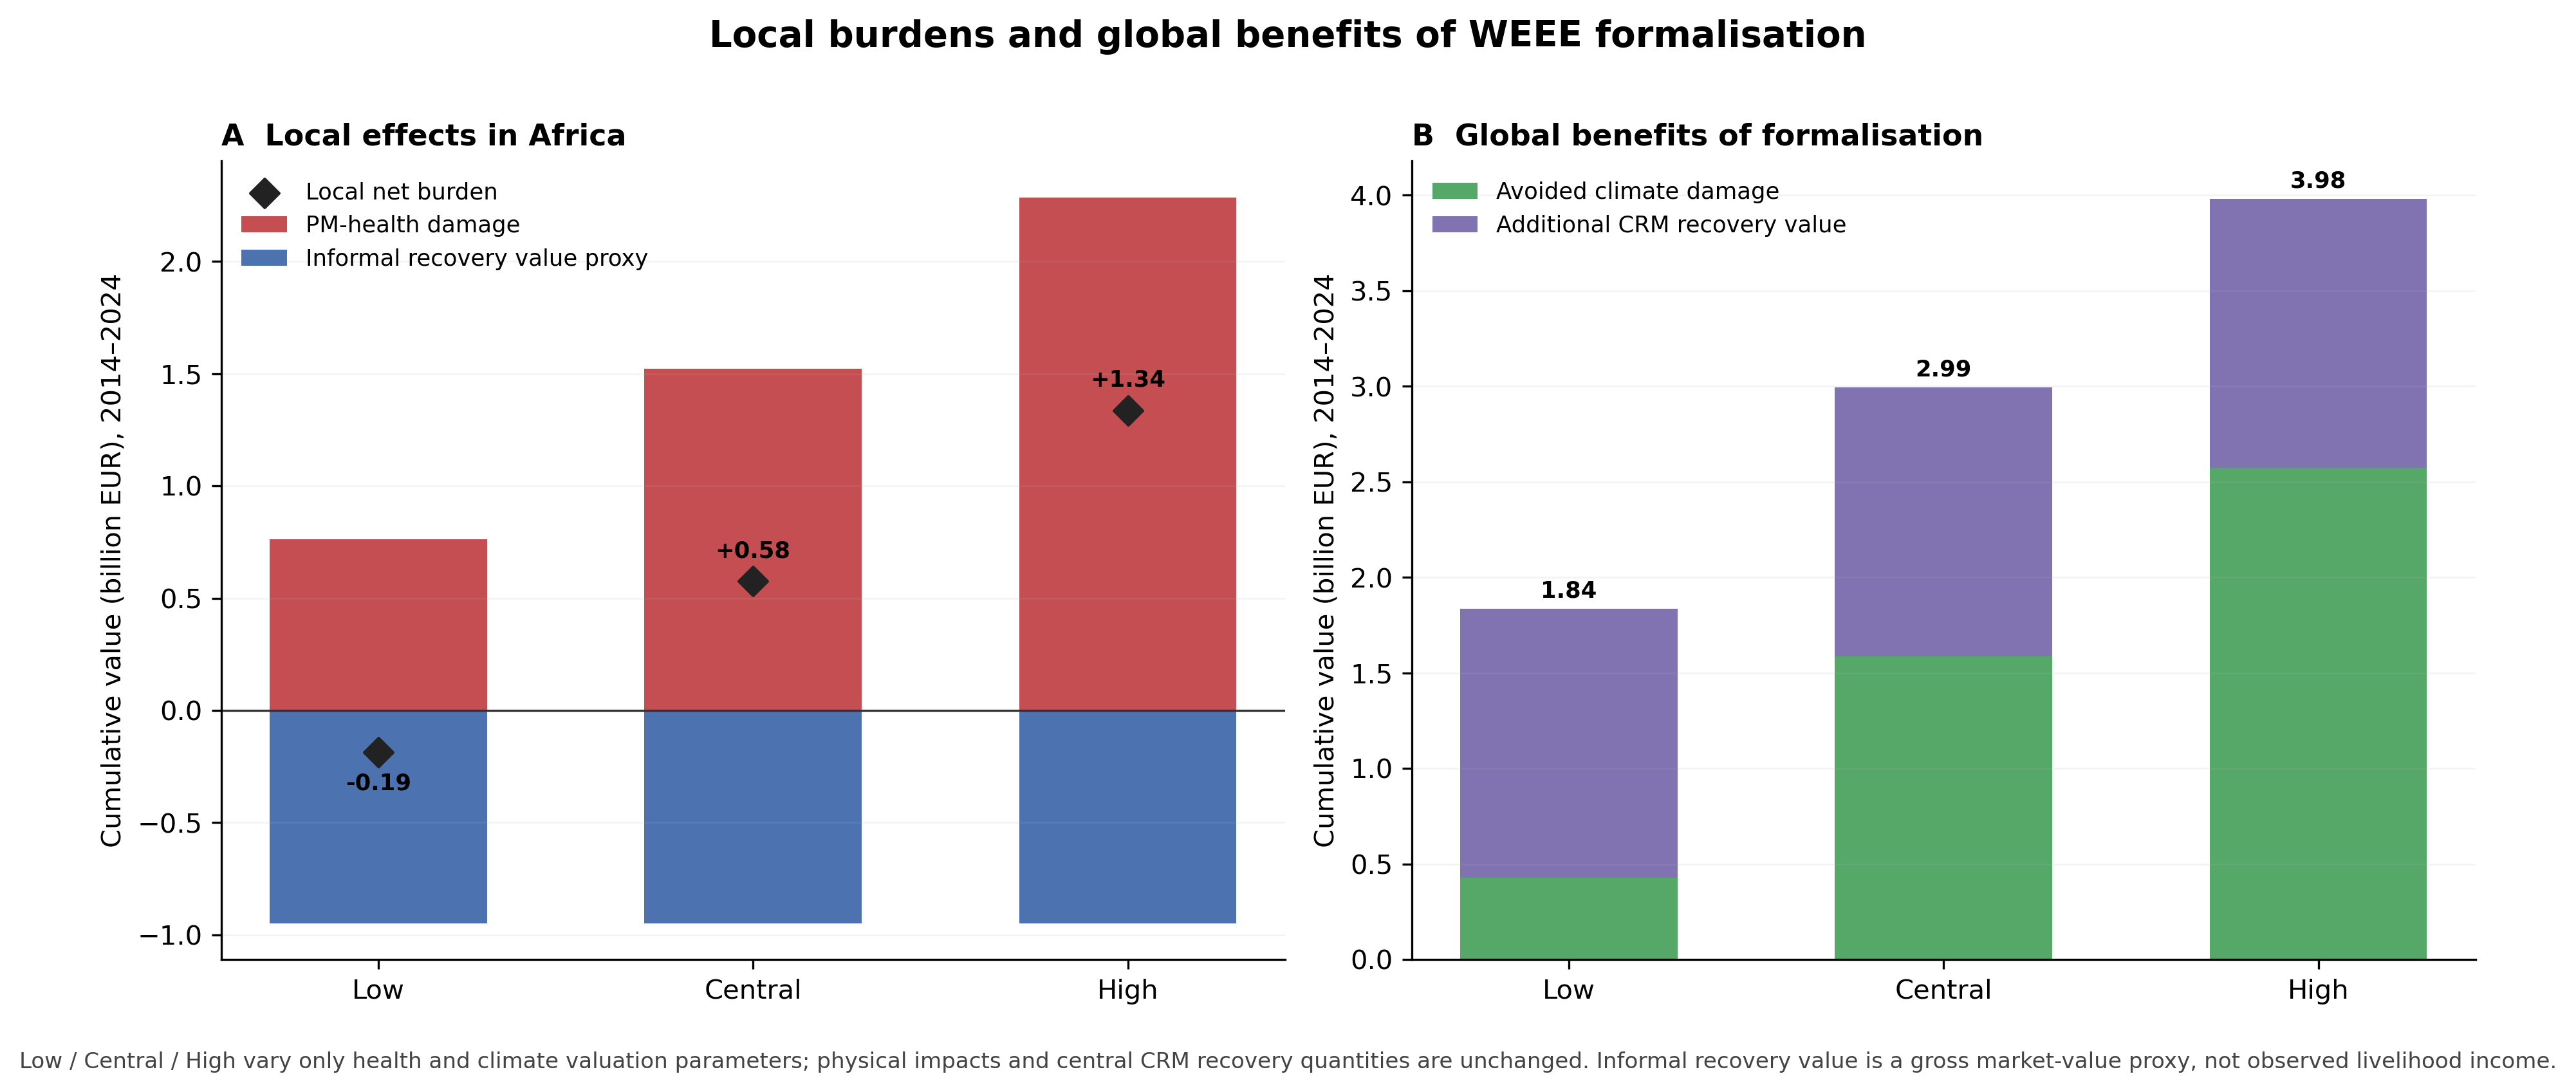

In [12]:
# CELL 11B — FIGURE 6: PUBLICATION-QUALITY LOCAL / GLOBAL DECOMPOSITION

cases = ["Low","Central","High"]
S = local_global_summary.set_index("Valuation_case")
x = np.arange(len(cases))

health = np.array([S.loc[c,"Local_PM_health_damage_EUR"]/1e9 for c in cases])
informal = np.array([S.loc[c,"Informal_recovery_value_EUR"]/1e9 for c in cases])
local_net = health - informal
climate = np.array([S.loc[c,"Global_climate_benefit_EUR"]/1e9 for c in cases])
crm_global = np.array([S.loc[c,"Additional_CRM_value_EUR"]/1e9 for c in cases])
global_total = climate + crm_global

fig, axes = plt.subplots(1,2,figsize=(12.6,5.2),dpi=300)

# Panel A — local
ax=axes[0]
ax.bar(x,health,width=.58,color="#C44E52",label="PM-health damage")
ax.bar(x,-informal,width=.58,color="#4C72B0",label="Informal recovery value proxy")
ax.scatter(x,local_net,s=58,marker="D",color="#222222",zorder=5,label="Local net burden")
ax.axhline(0,color="#333333",lw=.8)
ax.set_xticks(x,cases)
ax.set_ylabel("Cumulative value (billion EUR), 2014–2024")
ax.set_title("A  Local effects in Africa",loc="left",weight="bold")
ax.grid(axis="y",alpha=.15,lw=.6)
ax.legend(frameon=False,fontsize=8.5,loc="upper left")
for i,v in enumerate(local_net):
    ax.annotate(f"{v:+.2f}",(x[i],v),xytext=(0,9 if v>=0 else -14),
                textcoords="offset points",ha="center",fontsize=8.5,weight="bold")

# Panel B — global
ax=axes[1]
ax.bar(x,climate,width=.58,color="#55A868",label="Avoided climate damage")
ax.bar(x,crm_global,width=.58,bottom=climate,color="#8172B2",
       label="Additional CRM recovery value")
ax.set_xticks(x,cases)
ax.set_ylabel("Cumulative value (billion EUR), 2014–2024")
ax.set_title("B  Global benefits of formalisation",loc="left",weight="bold")
ax.grid(axis="y",alpha=.15,lw=.6)
ax.legend(frameon=False,fontsize=8.5,loc="upper left")
for i,v in enumerate(global_total):
    ax.text(x[i],v+.06,f"{v:.2f}",ha="center",fontsize=8.5,weight="bold")

fig.suptitle("Local burdens and global benefits of WEEE formalisation",
             fontsize=13.5,weight="bold",y=1.01)
fig.text(.5,-.035,
         "Low / Central / High vary only health and climate valuation parameters; "
         "physical impacts and central CRM recovery quantities are unchanged. "
         "Informal recovery value is a gross market-value proxy, not observed livelihood income.",
         ha="center",fontsize=8.2,color="#444444")

plt.tight_layout()
plt.savefig(FIG_DIR/"fig6_local_global_economic_accounting.pdf",bbox_inches="tight")
plt.savefig(FIG_DIR/"fig6_local_global_economic_accounting.png",bbox_inches="tight")
plt.show()

# Figure 7 — Mapping the local and global accounts

The Central valuation is mapped country by country, following the same accounting as Figure 6.

- **Panel A — Local effects:** PM-health damage under current informal management minus the informal-recovery market-value proxy.
- **Panel B — Global effects:** avoided climate damage plus additional CRM recovery value associated with formalisation.

Panel B is a map of the **country of WEEE generation associated with the global benefit**, not a map of where climate or mineral benefits are ultimately captured.

The map therefore visualizes the spatial origin of the modeled consequences while preserving the distinction between locally concentrated health/livelihood effects and broader climate/resource effects.

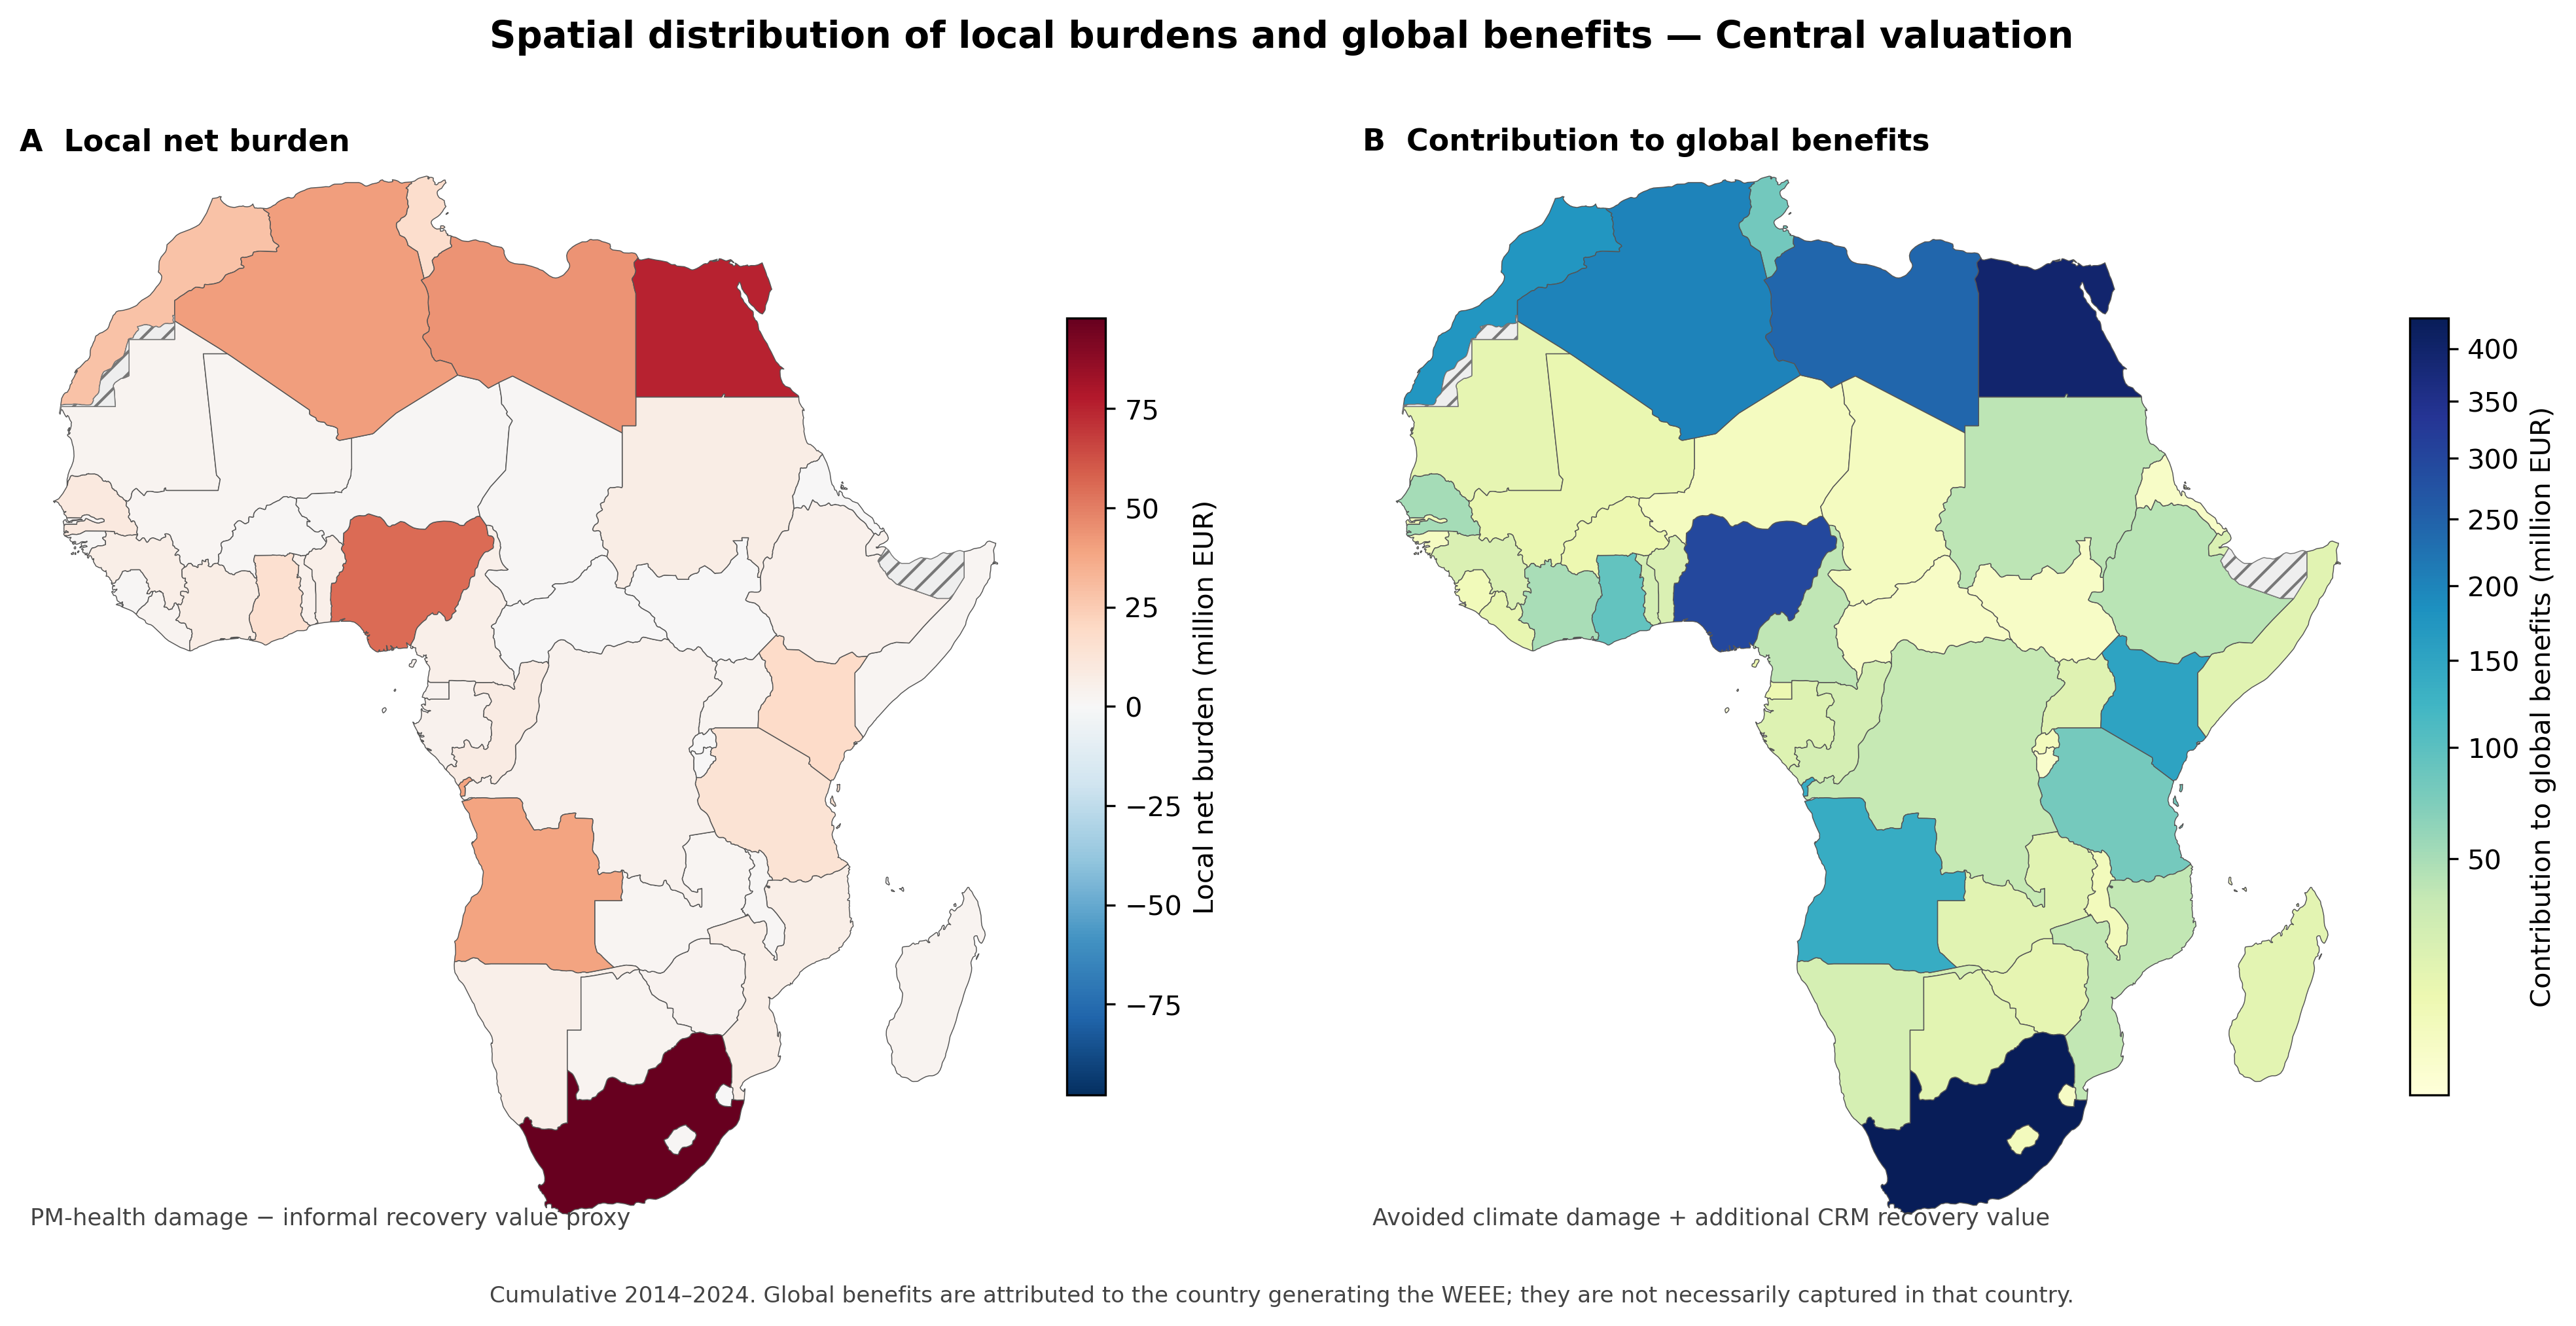

In [13]:
# CELL 12 — FIGURE 7: HIGH-QUALITY TWO-PANEL AFRICA MAP

from matplotlib.colors import TwoSlopeNorm, PowerNorm

central_map = local_global_country[
    local_global_country["Valuation_case"]=="Central"
].copy()

fig, axes = plt.subplots(1,2,figsize=(13.8,6.7),dpi=300)

try:
    import geopandas as gpd

    NE_URL="https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip"
    world=gpd.read_file(NE_URL)
    world["iso3"]=np.nan
    for c in [c for c in ["ISO_A3","ADM0_A3","SOV_A3"] if c in world.columns]:
        world["iso3"]=world["iso3"].fillna(world[c].replace("-99",np.nan))

    africa=world[world["CONTINENT"]=="Africa"].copy()
    africa=africa.merge(central_map,left_on="iso3",right_on="ISO3",how="left")

    # A: local, diverging around zero
    local_m=africa["Local_net_burden_EUR"]/1e6
    vmax=max(abs(local_m.dropna().min()),abs(local_m.dropna().max()))
    normA=TwoSlopeNorm(vmin=-vmax,vcenter=0,vmax=vmax)
    africa.assign(_v=local_m).plot(
        column="_v",cmap="RdBu_r",norm=normA,linewidth=.35,edgecolor="#555555",
        ax=axes[0],missing_kwds={"color":"#EEEEEE","edgecolor":"#777777","hatch":"///"}
    )
    sm=mpl.cm.ScalarMappable(cmap="RdBu_r",norm=normA); sm.set_array([])
    cb=fig.colorbar(sm,ax=axes[0],shrink=.72,pad=.015)
    cb.set_label("Local net burden (million EUR)")
    axes[0].set_title("A  Local net burden",loc="left",weight="bold")
    axes[0].text(.01,.02,"PM-health damage − informal recovery value proxy",
                 transform=axes[0].transAxes,fontsize=8.5,color="#444444")
    axes[0].set_xlim(-20,55); axes[0].set_ylim(-37,38); axes[0].axis("off")

    # B: global, positive and skewed
    global_m=africa["Global_benefit_EUR"]/1e6
    positive=global_m.dropna()
    normB=PowerNorm(gamma=.55,vmin=max(positive.min(),1e-12),vmax=positive.max())
    africa.assign(_v=global_m).plot(
        column="_v",cmap="YlGnBu",norm=normB,linewidth=.35,edgecolor="#555555",
        ax=axes[1],missing_kwds={"color":"#EEEEEE","edgecolor":"#777777","hatch":"///"}
    )
    sm=mpl.cm.ScalarMappable(cmap="YlGnBu",norm=normB); sm.set_array([])
    cb=fig.colorbar(sm,ax=axes[1],shrink=.72,pad=.015)
    cb.set_label("Contribution to global benefits (million EUR)")
    axes[1].set_title("B  Contribution to global benefits",loc="left",weight="bold")
    axes[1].text(.01,.02,"Avoided climate damage + additional CRM recovery value",
                 transform=axes[1].transAxes,fontsize=8.5,color="#444444")
    axes[1].set_xlim(-20,55); axes[1].set_ylim(-37,38); axes[1].axis("off")

except Exception as exc:
    for ax in axes:
        ax.text(.5,.5,f"Map not rendered:\n{exc}",ha="center",va="center")
        ax.axis("off")
    warnings.warn(str(exc))

fig.suptitle("Spatial distribution of local burdens and global benefits — Central valuation",
             fontsize=13.5,weight="bold",y=.99)
fig.text(.5,.015,
         "Cumulative 2014–2024. Global benefits are attributed to the country generating the WEEE; "
         "they are not necessarily captured in that country.",
         ha="center",fontsize=8.2,color="#444444")

plt.tight_layout(rect=[0,.035,1,.95])
plt.savefig(FIG_DIR/"fig7_local_global_maps_central.pdf",bbox_inches="tight")
plt.savefig(FIG_DIR/"fig7_local_global_maps_central.png",bbox_inches="tight")
plt.show()

# Headline results for manuscript

The output below is the preferred numerical source for the next manuscript revision. It replaces manually copied values from the old monolithic model.

In [14]:
# CELL 13 — HEADLINE RESULTS TABLE

ew_2024=ewaste.loc[ewaste["Year"]==YEAR1,"EWasteGenerated_kg"].sum()/1e9
ew_cum=ewaste["EWasteGenerated_kg"].sum()/1e9

central_val=valuation.set_index("Valuation_case").loc["Central"]

rows=[
    ["WEEE generated in final year",ew_2024,"Mt yr-1","Physical","Notebook 02"],
    ["Cumulative WEEE generated",ew_cum,"Mt","Physical","Notebook 02"],
    ["PM-health burden, current informal management",lca_sum.loc[S_CURRENT,"PM_DALY"],"DALY","Local","Notebook 03"],
    ["Potential PM-health reduction under formal treatment",delta_daly,"DALY","Local","Notebook 03"],
    ["GWP, current informal management",lca_sum.loc[S_CURRENT,"GWP_kgCO2eq"]/1e9,"Mt CO2-eq","Global","Notebook 03"],
    ["Potential GWP reduction under formal treatment",delta_tco2/1e6,"Mt CO2-eq","Global","Notebook 03"],
    ["Central monetised local health benefit",central_val["Health_local_EUR"]/1e9,"billion EUR","Local","Notebook 06 valuation"],
    ["Central monetised global climate benefit",central_val["Climate_global_EUR"]/1e9,"billion EUR","Global","Notebook 06 valuation"],
    ["CRM additional recovery market value",central_val["CRM_global_resource_value_EUR"]/1e9,"billion EUR","Global resource value","Notebook 06 valuation"],
    ["Central total partial monetised benefit",central_val["Total_partial_benefit_EUR"]/1e9,"billion EUR","Local + global","Notebook 06 valuation"],
]
headline=pd.DataFrame(rows,columns=["Quantity","Value","Unit","Spatial_interpretation","Source"])
headline.to_csv(TABLE_DIR/"headline_results.csv",index=False)
display(headline)

,Quantity,Value,Unit,Spatial_interpretation,Source
0,WEEE generated in final year,1.939478,Mt yr-1,Physical,Notebook 02
1,Cumulative WEEE generated,16.927311,Mt,Physical,Notebook 02
2,"PM-health burden, current informal management",15235.986580,DALY,Local,Notebook 03
3,Potential PM-health reduction under formal tre...,12304.571058,DALY,Local,Notebook 03
4,"GWP, current informal management",11.773108,Mt CO2-eq,Global,Notebook 03
5,Potential GWP reduction under formal treatment,8.578201,Mt CO2-eq,Global,Notebook 03
6,Central monetised local health benefit,1.230457,billion EUR,Local,Notebook 06 valuation
7,Central monetised global climate benefit,1.586967,billion EUR,Global,Notebook 06 valuation
8,CRM additional recovery market value,1.406112,billion EUR,Global resource value,Notebook 06 valuation
9,Central total partial monetised benefit,4.223537,billion EUR,Local + global,Notebook 06 valuation


# Recommended Q1 manuscript figure hierarchy

### Main text
1. **Figure 1 — EEE imports and WEEE generation by product group**
2. **Figure 2 — Geography of WEEE generation**
3. **Figure 3 — Local PM-health burden vs global climate burden**
4. **Figure 4 — Product-group drivers of current burdens**
5. **Figure 5 — CRM availability and additional recovery potential**
6. **Figure 6 — Local versus global economic accounting**
7. **Figure 7 — Two-map distribution of local net burden and global-benefit contribution**

Figure 6 is the principal economic figure. Figure 7 answers the spatial/distributional question directly.  
Low/Central/High are valuation scenarios, not uncertainty intervals or alternative physical systems.

## Publication note — commodity prices and currency conversion

CRM valuation uses historical international reference prices rather than a current spot quotation.

- **Cu, Au and Ag:** World Bank *Commodity Price Data (Pink Sheet)* / corresponding international benchmark series.
- **Pd:** USGS platinum-group-metals annual-average market-price statistics.
- **Currency conversion:** ECB annual-average USD/EUR reference exchange rate, series `EXR.A.USD.EUR.SP00.A`.

For every year from **2014 through 2024**, the annual USD commodity price is converted to EUR using the ECB annual-average exchange rate for that same year. The central CRM reference price is then the arithmetic mean of the resulting eleven annual EUR/kg observations.

This is a historical **nominal market-value** convention. The notebook therefore does not label these values as constant EUR2024. The valuation is intended as a transparent screening translation of physical CRM recovery potential into international market value.

CRM value remains conceptually global: the model does not assume that the full market value would be captured within Africa.

In [15]:
# ============================================================
# FINAL PUBLICATION EXPORT — 06B JESSICA FRAMING
# ============================================================

EXPORT_FILE = (
    TABLE_DIR /
    "ALL_RESULTS_FOR_PAPER_REVIEW_06B_JESSICA.xlsx"
)


# ============================================================
# 1. REQUIRED 06B OBJECTS
# ============================================================

required_06b = [
    "local_global_summary",
    "local_global_country",
    "crm_country",
    "crm_detail",
]

missing_06b = [
    x for x in required_06b
    if x not in globals()
]

assert not missing_06b, (
    "Run CELL 11A first. Missing objects: "
    f"{missing_06b}"
)


# ============================================================
# 2. WEEE SUMMARIES
# ============================================================

ewaste_africa_product = (
    ewaste
    .groupby(
        ["Year", "ProductGroup"],
        as_index=False
    )["EWasteGenerated_kg"]
    .sum()
)

ewaste_africa_product["EWaste_Mt"] = (
    ewaste_africa_product["EWasteGenerated_kg"]
    / 1e9
)


ewaste_country = (
    ewaste
    .groupby(
        ["ISO3", "Country"],
        as_index=False
    )["EWasteGenerated_kg"]
    .sum()
)

ewaste_country["EWaste_Mt"] = (
    ewaste_country["EWasteGenerated_kg"]
    / 1e9
)

ewaste_country = (
    ewaste_country
    .sort_values(
        "EWasteGenerated_kg",
        ascending=False
    )
)


# ============================================================
# 3. CRM ECONOMIC VALUE BY METAL
# ============================================================

crm_economic = pd.DataFrame({

    "CRM":
        list(crm_value_by_metal.keys()),

    "Additional_recoverable_kg":
        [
            crm_physical_kg[m]
            for m in crm_value_by_metal
        ],

    "Historical_mean_price_EUR_per_kg":
        [
            CRM_PRICE_EUR_PER_KG[m]
            for m in crm_value_by_metal
        ],

    "Resource_market_value_EUR":
        [
            crm_value_by_metal[m]
            for m in crm_value_by_metal
        ],
})

crm_economic[
    "Resource_market_value_million_EUR"
] = (
    crm_economic[
        "Resource_market_value_EUR"
    ] / 1e6
)


# ============================================================
# 4. COUNTRY HEALTH TABLE
# Reconstructed directly from physical comparison results
# ============================================================

country_health = (
    comparison
    .groupby(
        ["Country", "ISO3", "Region"],
        as_index=False
    )
    .agg(

        PM_DALY_informal=(
            "PM_DALY_Africa_informal",
            "sum"
        ),

        PM_DALY_formal=(
            "PM_DALY_Africa_formal",
            "sum"
        ),
    )
)

country_health["PM_DALY_reduction"] = (
    country_health["PM_DALY_informal"]
    - country_health["PM_DALY_formal"]
)

country_health[
    "Potential_health_benefit_central_EUR"
] = (
    country_health["PM_DALY_reduction"]
    * HEALTH_VALUE_EUR_PER_DALY["Central"]
)


# ============================================================
# 5. CENTRAL LOCAL / GLOBAL COUNTRY TABLE
# ============================================================

central_country_06b = (
    local_global_country[
        local_global_country[
            "Valuation_case"
        ] == "Central"
    ]
    .copy()
)


# ============================================================
# 6. JESSICA-FRAMING HEADLINE TABLE
# ============================================================

central_row = (
    local_global_summary[
        local_global_summary[
            "Valuation_case"
        ] == "Central"
    ]
    .iloc[0]
)


headline_local_global = pd.DataFrame({

    "Metric": [

        "PM-health damage under current informal management",

        "Informal recovery market-value proxy",

        "Local net burden",

        "Avoided climate damage under formalisation",

        "Additional CRM recovery value",

        "Global benefit of formalisation",
    ],

    "Value_billion_EUR": [

        central_row[
            "Local_PM_health_damage_EUR"
        ] / 1e9,

        central_row[
            "Informal_recovery_value_EUR"
        ] / 1e9,

        central_row[
            "Local_net_burden_EUR"
        ] / 1e9,

        central_row[
            "Global_climate_benefit_EUR"
        ] / 1e9,

        central_row[
            "Additional_CRM_value_EUR"
        ] / 1e9,

        central_row[
            "Global_benefit_EUR"
        ] / 1e9,
    ],

    "Account": [

        "Local",
        "Local",
        "Local",
        "Global",
        "Global",
        "Global",
    ],

    "Interpretation": [

        (
            "Monetised PM-related health burden "
            "under current informal management"
        ),

        (
            "Gross reference-market value of "
            "informally recovered Cu, Ag, Au and Pd; "
            "proxy for livelihood-related economic "
            "value, not observed worker income"
        ),

        (
            "PM-health damage minus informal "
            "recovery market-value proxy"
        ),

        (
            "Potential climate benefit from lower "
            "GHG emissions under formal treatment"
        ),

        (
            "Market value of additional Cu, Ag, Au "
            "and Pd recovery under formal treatment"
        ),

        (
            "Avoided climate damage plus additional "
            "CRM recovery value"
        ),
    ]
})


# ============================================================
# 7. ASSUMPTIONS — 06B
# ============================================================

assumptions = []


for case, value in HEALTH_VALUE_EUR_PER_DALY.items():

    assumptions.append({

        "Parameter":
            "Value per DALY",

        "Case":
            case,

        "Value":
            value,

        "Unit":
            "EUR/DALY",

        "Source_or_method":
            "Screening valuation scenario",

        "Spatial_interpretation":
            "Local air-pollution account"
    })


for case, value in SCC_EUR_PER_TCO2.items():

    assumptions.append({

        "Parameter":
            "Social cost of carbon",

        "Case":
            case,

        "Value":
            value,

        "Unit":
            "EUR/t CO2-eq",

        "Source_or_method":
            "Screening valuation scenario",

        "Spatial_interpretation":
            "Global climate account"
    })


for metal, value in CRM_PRICE_EUR_PER_KG.items():

    source = (
        crm_reference_prices
        .set_index("CRM")
        .loc[
            metal,
            "Commodity_price_source"
        ]
    )

    assumptions.append({

        "Parameter":
            f"{metal} CRM reference price",

        "Case":
            "Mean annual price, 2014–2024",

        "Value":
            value,

        "Unit":
            "EUR/kg",

        "Source_or_method":
            (
                f"{source}; annual FX: "
                "ECB EXR.A.USD.EUR.SP00.A"
            ),

        "Spatial_interpretation":
            "Material recovery valuation"
    })


assumptions.extend([

    {

        "Parameter":
            "Local effects",

        "Case":
            "All valuation cases",

        "Value":
            np.nan,

        "Unit":
            "EUR",

        "Source_or_method":
            (
                "PM-health damage under current "
                "informal management minus informal "
                "recovery × metal price"
            ),

        "Spatial_interpretation":
            "Local effects in Africa"
    },

    {

        "Parameter":
            "Informal recovery value",

        "Case":
            "Central recovery rates",

        "Value":
            np.nan,

        "Unit":
            "EUR",

        "Source_or_method":
            (
                "Informally recovered Cu, Ag, Au "
                "and Pd × historical mean "
                "reference prices"
            ),

        "Spatial_interpretation":
            (
                "Proxy for livelihood-related "
                "economic value; not observed income"
            )
    },

    {

        "Parameter":
            "Global effects",

        "Case":
            "All valuation cases",

        "Value":
            np.nan,

        "Unit":
            "EUR",

        "Source_or_method":
            (
                "Avoided GHG damage + value of "
                "additional CRM recovery under "
                "formal treatment"
            ),

        "Spatial_interpretation":
            "Global / broader effects"
    },

])

assumptions = pd.DataFrame(assumptions)


# ============================================================
# 8. PUBLICATION AUDIT
# ============================================================

audit = pd.DataFrame([

    [
        "Observation period",
        f"{YEAR0}–{YEAR1}",
        "Physical model"
    ],

    [
        "Electricity intermittency baseline",
        bool(
            meta02.get(
                "apply_electricity_adjustment"
            )
        ),
        "Notebook 02"
    ],

    [
        "Avoided primary production credits included",
        bool(
            meta03.get(
                "avoided_primary_production_credits_included"
            )
        ),
        "Notebook 03"
    ],

    [
        "Monetization inside physical LCA",
        bool(
            meta03.get(
                "monetization_included"
            )
        ),
        "Notebook 03"
    ],

    [
        "CRM recovery subset",
        ", ".join(
            sorted(
                meta05.get(
                    "crm_codes_with_recovery_scenarios",
                    []
                )
            )
        ),
        "Notebook 05"
    ],

    [
        "Local accounting",
        (
            "PM-health damage minus informal "
            "recovery market value"
        ),
        "Notebook 06B"
    ],

    [
        "Informal recovery interpretation",
        (
            "Proxy for livelihood-related economic "
            "value; not observed worker income"
        ),
        "Notebook 06B"
    ],

    [
        "Global accounting",
        (
            "Avoided climate damage plus additional "
            "CRM recovery value"
        ),
        "Notebook 06B"
    ],

    [
        "Low/Central/High",
        (
            "Valuation cases only; physical "
            "quantities unchanged"
        ),
        "Notebook 06B"
    ],

    [
        "CRM price period",
        "2014–2024",
        "Notebook 06B"
    ],

    [
        "CRM annual FX method",
        (
            "Same-year ECB annual-average "
            "USD/EUR"
        ),
        "Notebook 06B"
    ],

    [
        "Local and global accounts added together",
        "No",
        "Notebook 06B"
    ],

    [
        "Avoided-primary environmental benefits monetised",
        "No",
        "Notebook 06B"
    ],

    [
        "Formal-system CAPEX/OPEX included",
        "No",
        "Notebook 06B"
    ],

], columns=[
    "Check",
    "Value",
    "Source"
])


# ============================================================
# 9. WRITE FINAL 06B EXCEL
# ============================================================

with pd.ExcelWriter(
    EXPORT_FILE,
    engine="openpyxl"
) as writer:

    # Jessica framing first
    headline_local_global.to_excel(
        writer,
        sheet_name="00_LOCAL_GLOBAL_HEADLINE",
        index=False
    )

    local_global_summary.to_excel(
        writer,
        sheet_name="01_LOCAL_GLOBAL_CASES",
        index=False
    )

    central_country_06b.to_excel(
        writer,
        sheet_name="02_COUNTRY_CENTRAL",
        index=False
    )

    local_global_country.to_excel(
        writer,
        sheet_name="03_COUNTRY_ALL_CASES",
        index=False
    )

    # Physical headline results
    headline.to_excel(
        writer,
        sheet_name="04_PHYSICAL_HEADLINE",
        index=False
    )

    audit.to_excel(
        writer,
        sheet_name="05_PUBLICATION_AUDIT",
        index=False
    )

    assumptions.to_excel(
        writer,
        sheet_name="06_ASSUMPTIONS",
        index=False
    )

    # CRM
    crm_country.to_excel(
        writer,
        sheet_name="07_CRM_COUNTRY",
        index=False
    )

    crm_detail.to_excel(
        writer,
        sheet_name="08_CRM_DETAIL",
        index=False
    )

    crm_economic.to_excel(
        writer,
        sheet_name="09_CRM_ECONOMIC",
        index=False
    )

    crm_reference_prices.to_excel(
        writer,
        sheet_name="10_CRM_PRICE_MEANS",
        index=False
    )

    if "crm_price_history" in globals():

        crm_price_history.to_excel(
            writer,
            sheet_name="11_CRM_PRICE_HISTORY",
            index=False
        )

    crm_available_cum.to_excel(
        writer,
        sheet_name="12_CRM_AVAILABLE",
        index=False
    )

    crm_additional.to_excel(
        writer,
        sheet_name="13_CRM_RECOVERY",
        index=False
    )

    # LCA
    africa_lcia.to_excel(
        writer,
        sheet_name="14_AFRICA_LCIA",
        index=False
    )

    country_lcia.to_excel(
        writer,
        sheet_name="15_COUNTRY_LCIA",
        index=False
    )

    product_lcia.to_excel(
        writer,
        sheet_name="16_PRODUCT_LCIA",
        index=False
    )

    comparison.to_excel(
        writer,
        sheet_name="17_FORMAL_VS_INFORMAL",
        index=False
    )

    # Health
    country_health.to_excel(
        writer,
        sheet_name="18_COUNTRY_HEALTH",
        index=False
    )

    # WEEE
    ewaste_africa_product.to_excel(
        writer,
        sheet_name="19_WEEE_PRODUCT",
        index=False
    )

    ewaste_country.to_excel(
        writer,
        sheet_name="20_WEEE_COUNTRY",
        index=False
    )

    ewaste.to_excel(
        writer,
        sheet_name="21_WEEE_FULL",
        index=False
    )


# ============================================================
# 10. DISPLAY FINAL RESULTS
# ============================================================

print("=" * 78)
print("06B — JESSICA FRAMING — PUBLICATION EXPORT CREATED")
print("=" * 78)

print(EXPORT_FILE)


print("\nLOCAL / GLOBAL HEADLINE — CENTRAL")
display(headline_local_global)


print("\nLOCAL / GLOBAL — LOW / CENTRAL / HIGH")

display(
    local_global_summary.assign(
        **{
            c:
                local_global_summary[c] / 1e9

            for c
            in local_global_summary.columns

            if c.endswith("_EUR")
        }
    )
)


print("\nTOP COUNTRIES — CENTRAL LOCAL EFFECTS")

display(
    central_country_06b[
        [
            "Country",
            "ISO3",
            "Local_PM_health_damage_EUR",
            "Informal_recovery_value_EUR",
            "Local_net_burden_EUR",
        ]
    ]
    .sort_values(
        "Local_net_burden_EUR",
        ascending=False
    )
    .head(15)
)


print("\nTOP COUNTRIES — CENTRAL GLOBAL EFFECTS")

display(
    central_country_06b[
        [
            "Country",
            "ISO3",
            "Global_climate_benefit_EUR",
            "Additional_CRM_value_EUR",
            "Global_benefit_EUR",
        ]
    ]
    .sort_values(
        "Global_benefit_EUR",
        ascending=False
    )
    .head(15)
)


print("\nPUBLICATION AUDIT")
display(audit)

06B — JESSICA FRAMING — PUBLICATION EXPORT CREATED
C:\Users\uribep_a\OneDrive - Paul Scherrer Institut\general_LCA\06B_paper_outputs\tables\ALL_RESULTS_FOR_PAPER_REVIEW_06B_JESSICA.xlsx

LOCAL / GLOBAL HEADLINE — CENTRAL


,Metric,Value_billion_EUR,Account,Interpretation
0,PM-health damage under current informal manage...,1.523599,Local,Monetised PM-related health burden under curre...
1,Informal recovery market-value proxy,0.948258,Local,Gross reference-market value of informally rec...
2,Local net burden,0.575341,Local,PM-health damage minus informal recovery marke...
3,Avoided climate damage under formalisation,1.586967,Global,Potential climate benefit from lower GHG emiss...
4,Additional CRM recovery value,1.406112,Global,"Market value of additional Cu, Ag, Au and Pd r..."
5,Global benefit of formalisation,2.993079,Global,Avoided climate damage plus additional CRM rec...



LOCAL / GLOBAL — LOW / CENTRAL / HIGH


,Valuation_case,Local_PM_health_damage_EUR,Informal_recovery_value_EUR,Local_net_burden_EUR,Global_climate_benefit_EUR,Additional_CRM_value_EUR,Global_benefit_EUR
0,Low,0.761799,0.948258,-0.186459,0.428910,1.406112,1.835022
1,Central,1.523599,0.948258,0.575341,1.586967,1.406112,2.993079
2,High,2.285398,0.948258,1.337140,2.573460,1.406112,3.979572



TOP COUNTRIES — CENTRAL LOCAL EFFECTS


,Country,ISO3,Local_PM_health_damage_EUR,Informal_recovery_value_EUR,Local_net_burden_EUR
99,South Africa,ZAF,2.345722e+08,1.367371e+08,9.783510e+07
69,Egypt,EGY,1.942296e+08,1.189134e+08,7.531616e+07
92,Nigeria,NGA,1.513517e+08,9.581607e+07,5.553565e+07
82,Libya,LBY,1.194395e+08,7.520089e+07,4.423866e+07
54,Algeria,DZA,1.027700e+08,6.178939e+07,4.098056e+07
55,Angola,AGO,8.011368e+07,4.078761e+07,3.932608e+07
88,Morocco,MAR,8.135786e+07,5.271776e+07,2.864010e+07
79,Kenya,KEN,6.944345e+07,5.062151e+07,1.882194e+07
104,Tunisia,TUN,4.104018e+07,2.421263e+07,1.682755e+07
76,Ghana,GHA,4.831101e+07,3.230414e+07,1.600687e+07



TOP COUNTRIES — CENTRAL GLOBAL EFFECTS


,Country,ISO3,Global_climate_benefit_EUR,Additional_CRM_value_EUR,Global_benefit_EUR
99,South Africa,ZAF,2.235580e+08,2.069010e+08,4.304590e+08
69,Egypt,EGY,2.181864e+08,1.786383e+08,3.968247e+08
92,Nigeria,NGA,1.558984e+08,1.410474e+08,2.969458e+08
82,Libya,LBY,1.339915e+08,1.091127e+08,2.431043e+08
54,Algeria,DZA,1.149933e+08,8.702498e+07,2.020183e+08
88,Morocco,MAR,9.174198e+07,8.294430e+07,1.746863e+08
79,Kenya,KEN,7.475119e+07,7.827395e+07,1.530251e+08
55,Angola,AGO,8.147822e+07,5.608990e+07,1.375681e+08
76,Ghana,GHA,4.758683e+07,4.708866e+07,9.467549e+07
104,Tunisia,TUN,4.706241e+07,3.461426e+07,8.167667e+07



PUBLICATION AUDIT


,Check,Value,Source
0,Observation period,2014–2024,Physical model
1,Electricity intermittency baseline,True,Notebook 02
2,Avoided primary production credits included,False,Notebook 03
3,Monetization inside physical LCA,False,Notebook 03
4,CRM recovery subset,"Ag, Au, Cu, Pd",Notebook 05
5,Local accounting,PM-health damage minus informal recovery marke...,Notebook 06B
6,Informal recovery interpretation,Proxy for livelihood-related economic value; n...,Notebook 06B
7,Global accounting,Avoided climate damage plus additional CRM rec...,Notebook 06B
8,Low/Central/High,Valuation cases only; physical quantities unch...,Notebook 06B
9,CRM price period,2014–2024,Notebook 06B


# 06B publication export — local/global accounting

This export is the preferred source for manuscript revision of the local/global economic framing.

In [16]:
# ============================================================
# FINAL 06B COMPACT EXPORT — JESSICA LOCAL / GLOBAL FRAMING
# ============================================================

OUT06B = (
    TABLE_DIR /
    "ALL_RESULTS_FOR_PAPER_REVIEW_06B_LOCAL_GLOBAL_COMPACT.xlsx"
)


# ============================================================
# 1. CHECK REQUIRED OBJECTS
# ============================================================

required_objects = [
    "headline",
    "local_global_summary",
    "local_global_country",
    "crm_country",
    "crm_detail",
    "africa_lcia",
    "country_lcia",
    "product_lcia",
    "comparison",
    "ewaste",
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

assert not missing_objects, (
    "Missing required objects. "
    f"Run previous cells first: {missing_objects}"
)


# ============================================================
# 2. CENTRAL COUNTRY RESULTS
# ============================================================

central_country_06b = (
    local_global_country[
        local_global_country[
            "Valuation_case"
        ] == "Central"
    ]
    .copy()
)


# ============================================================
# 3. CRM PRICE MEANS
# ============================================================

# CELL 11A should already have created price_ref.
# If not, load it directly.

if "price_ref" not in globals():

    price_candidates = [
        TABLE_DIR /
        "crm_reference_prices_2014_2024_FINAL.csv",

        PROJECT_DIR /
        "crm_reference_prices_2014_2024_FINAL.csv",

        PROJECT_DIR /
        "06_paper_outputs" /
        "tables" /
        "crm_reference_prices_2014_2024_FINAL.csv",
    ]

    PRICE_FILE_06B = next(
        (
            p
            for p in price_candidates
            if p.exists()
        ),
        None
    )

    assert PRICE_FILE_06B is not None, (
        "Could not locate "
        "crm_reference_prices_2014_2024_FINAL.csv"
    )

    price_ref = pd.read_csv(
        PRICE_FILE_06B
    )


# ============================================================
# 4. OPTIONAL CRM PRICE HISTORY
# ============================================================

price_history_06b = None

if "crm_price_history" in globals():

    price_history_06b = (
        crm_price_history.copy()
    )

elif "price_history" in globals():

    price_history_06b = (
        price_history.copy()
    )

else:

    history_candidates = [
        TABLE_DIR /
        "crm_market_price_history_2014_2024_FINAL.csv",

        PROJECT_DIR /
        "crm_market_price_history_2014_2024_FINAL.csv",

        PROJECT_DIR /
        "06_paper_outputs" /
        "tables" /
        "crm_market_price_history_2014_2024_FINAL.csv",
    ]

    HISTORY_FILE_06B = next(
        (
            p
            for p in history_candidates
            if p.exists()
        ),
        None
    )

    if HISTORY_FILE_06B is not None:

        price_history_06b = pd.read_csv(
            HISTORY_FILE_06B
        )


# ============================================================
# 5. JESSICA LOCAL / GLOBAL METHOD
# ============================================================

local_global_assumptions = pd.DataFrame(
    [

        [
            "Local effects",

            (
                "PM-health damage under current informal "
                "management minus informal recovery × "
                "metal price"
            ),

            "Local account in Africa"
        ],

        [
            "Informal recovery value",

            (
                "Central informal recovery of Cu, Ag, Au "
                "and Pd × historical 2014–2024 mean "
                "reference prices"
            ),

            (
                "Proxy for livelihood-related economic "
                "value; not observed worker income"
            )
        ],

        [
            "Global effects",

            (
                "Avoided GHG damage under formalisation "
                "+ additional CRM recovery value"
            ),

            "Global / broader account"
        ],

        [
            "Net mineral recovery gain",

            (
                "Formal recovery minus informal recovery "
                "for Cu, Ag, Au and Pd"
            ),

            "Additional recovery under formal treatment"
        ],

        [
            "Low health valuation",
            50_000,
            "EUR/DALY"
        ],

        [
            "Central health valuation",
            100_000,
            "EUR/DALY"
        ],

        [
            "High health valuation",
            150_000,
            "EUR/DALY"
        ],

        [
            "Low SCC",
            50,
            "EUR/t CO2-eq"
        ],

        [
            "Central SCC",
            185,
            "EUR/t CO2-eq"
        ],

        [
            "High SCC",
            300,
            "EUR/t CO2-eq"
        ],

        [
            "Low / Central / High",

            (
                "Only health and climate monetary "
                "valuation parameters vary"
            ),

            (
                "Not physical scenarios and not "
                "confidence intervals"
            )
        ],

        [
            "CRM valuation",

            (
                "Historical 2014–2024 mean international "
                "reference prices with same-year ECB FX"
            ),

            "Physical CRM quantities unchanged across cases"
        ],

        [
            "Aggregation rule",

            (
                "Local and global accounts are reported "
                "separately"
            ),

            "They are not summed into a net social benefit"
        ],
    ],

    columns=[
        "Item",
        "Definition_or_value",
        "Interpretation_or_unit"
    ]
)


# ============================================================
# 6. COMPACT HEADLINE — CENTRAL
# ============================================================

central_row = (
    local_global_summary[
        local_global_summary[
            "Valuation_case"
        ] == "Central"
    ]
    .iloc[0]
)


local_global_headline = pd.DataFrame({

    "Account": [
        "Local",
        "Local",
        "Local",
        "Global",
        "Global",
        "Global",
    ],

    "Component": [

        "PM-health damage",

        "Informal recovery market-value proxy",

        "Local net burden",

        "Avoided climate damage",

        "Additional CRM recovery value",

        "Global benefit of formalisation",
    ],

    "Value_billion_EUR": [

        central_row[
            "Local_PM_health_damage_EUR"
        ] / 1e9,

        central_row[
            "Informal_recovery_value_EUR"
        ] / 1e9,

        central_row[
            "Local_net_burden_EUR"
        ] / 1e9,

        central_row[
            "Global_climate_benefit_EUR"
        ] / 1e9,

        central_row[
            "Additional_CRM_value_EUR"
        ] / 1e9,

        central_row[
            "Global_benefit_EUR"
        ] / 1e9,
    ]
})


# ============================================================
# 7. AUDIT
# ============================================================

assert len(
    local_global_summary[
        local_global_summary[
            "Valuation_case"
        ] == "Central"
    ]
) == 1


assert (
    central_country_06b[
        [
            "Local_PM_health_damage_EUR",
            "Informal_recovery_value_EUR",
            "Local_net_burden_EUR",
            "Global_climate_benefit_EUR",
            "Additional_CRM_value_EUR",
            "Global_benefit_EUR",
        ]
    ]
    .notna()
    .all()
    .all()
)


# Accounting identities

assert np.allclose(
    central_country_06b[
        "Local_net_burden_EUR"
    ],

    central_country_06b[
        "Local_PM_health_damage_EUR"
    ]
    -
    central_country_06b[
        "Informal_recovery_value_EUR"
    ]
)


assert np.allclose(
    central_country_06b[
        "Global_benefit_EUR"
    ],

    central_country_06b[
        "Global_climate_benefit_EUR"
    ]
    +
    central_country_06b[
        "Additional_CRM_value_EUR"
    ]
)


# ============================================================
# 8. WRITE COMPACT EXCEL
# ============================================================

with pd.ExcelWriter(
    OUT06B,
    engine="openpyxl"
) as writer:

    # Jessica's results FIRST

    local_global_headline.to_excel(
        writer,
        sheet_name="00_LOCAL_GLOBAL_HEADLINE",
        index=False
    )

    local_global_summary.to_excel(
        writer,
        sheet_name="01_LOCAL_GLOBAL_CASES",
        index=False
    )

    local_global_assumptions.to_excel(
        writer,
        sheet_name="02_METHOD",
        index=False
    )

    central_country_06b.to_excel(
        writer,
        sheet_name="03_COUNTRY_CENTRAL",
        index=False
    )

    local_global_country.to_excel(
        writer,
        sheet_name="04_COUNTRY_ALL_CASES",
        index=False
    )


    # CRM supporting data

    crm_country.to_excel(
        writer,
        sheet_name="05_CRM_COUNTRY",
        index=False
    )

    crm_detail.to_excel(
        writer,
        sheet_name="06_CRM_DETAIL",
        index=False
    )

    price_ref.to_excel(
        writer,
        sheet_name="07_CRM_PRICE_MEANS",
        index=False
    )


    if price_history_06b is not None:

        price_history_06b.to_excel(
            writer,
            sheet_name="08_CRM_PRICE_HISTORY",
            index=False
        )


    # Physical supporting data

    headline.to_excel(
        writer,
        sheet_name="09_PHYSICAL_HEADLINE",
        index=False
    )

    africa_lcia.to_excel(
        writer,
        sheet_name="10_AFRICA_LCIA",
        index=False
    )

    country_lcia.to_excel(
        writer,
        sheet_name="11_COUNTRY_LCIA",
        index=False
    )

    product_lcia.to_excel(
        writer,
        sheet_name="12_PRODUCT_LCIA",
        index=False
    )

    comparison.to_excel(
        writer,
        sheet_name="13_FORMAL_VS_INFORMAL",
        index=False
    )

    ewaste.to_excel(
        writer,
        sheet_name="14_WEEE_FULL",
        index=False
    )


# ============================================================
# 9. DISPLAY
# ============================================================

print("=" * 78)
print("06B COMPACT EXPORT — JESSICA FRAMING")
print("=" * 78)

print(OUT06B)


print("\nCENTRAL LOCAL / GLOBAL RESULTS")

display(
    local_global_headline
)


print("\nLOW / CENTRAL / HIGH — BILLION EUR")

display(
    local_global_summary.assign(
        **{
            c:
                local_global_summary[c] / 1e9

            for c
            in local_global_summary.columns

            if c.endswith("_EUR")
        }
    )
)


print("\nCHECK OF JESSICA'S ACCOUNTING")

print(
    "LOCAL  = air pollution "
    "− informal recovery × metal price"
)

print(
    "GLOBAL = avoided GHG damage "
    "+ net mineral recovery gain"
)

06B COMPACT EXPORT — JESSICA FRAMING
C:\Users\uribep_a\OneDrive - Paul Scherrer Institut\general_LCA\06B_paper_outputs\tables\ALL_RESULTS_FOR_PAPER_REVIEW_06B_LOCAL_GLOBAL_COMPACT.xlsx

CENTRAL LOCAL / GLOBAL RESULTS


,Account,Component,Value_billion_EUR
0,Local,PM-health damage,1.523599
1,Local,Informal recovery market-value proxy,0.948258
2,Local,Local net burden,0.575341
3,Global,Avoided climate damage,1.586967
4,Global,Additional CRM recovery value,1.406112
5,Global,Global benefit of formalisation,2.993079



LOW / CENTRAL / HIGH — BILLION EUR


,Valuation_case,Local_PM_health_damage_EUR,Informal_recovery_value_EUR,Local_net_burden_EUR,Global_climate_benefit_EUR,Additional_CRM_value_EUR,Global_benefit_EUR
0,Low,0.761799,0.948258,-0.186459,0.428910,1.406112,1.835022
1,Central,1.523599,0.948258,0.575341,1.586967,1.406112,2.993079
2,High,2.285398,0.948258,1.337140,2.573460,1.406112,3.979572



CHECK OF JESSICA'S ACCOUNTING
LOCAL  = air pollution − informal recovery × metal price
GLOBAL = avoided GHG damage + net mineral recovery gain


# Manuscript interpretation — preferred wording

The economic results should be presented as two distinct accounts rather than as a single net-benefit estimate.

**Local account.** Informal WEEE management generates PM-related health damages in African countries, while informal material recovery also creates economic value. We approximate the latter using the gross market value of informally recovered Cu, Ag, Au and Pd. This term is used as a proxy for livelihood-related economic value and should not be interpreted as observed income accruing to informal workers.

**Global account.** Formalisation can generate broader benefits through lower life-cycle greenhouse-gas emissions and greater recovery of valuable materials. We value the climate component using the social cost of carbon and the resource component as the market value of additional Cu, Ag, Au and Pd recovered under the formal-treatment counterfactual.

The two accounts are intentionally kept separate. The local account characterizes the balance between locally borne air-pollution damages and livelihood-related recovery value under current informal management, whereas the global account measures potential climate and resource benefits from formalisation. Their juxtaposition illustrates the spatial mismatch between where important burdens are borne and where the rationale for improved WEEE management extends beyond national boundaries.